# Research I — Follow-up Experiments (H1–H5)

**Purpose:** test explanations and operating-point sensitivity identified in notebook `06_levir_hypotheses_H1_H5.ipynb`, using the same six deployed checkpoints and cached inference scores. **No training, HPO, checkpoint modifications, or new dataset downloads.**

**What is genuinely new here?** Threshold sensitivity of **Component Recall vs actual operator alert counts**, failure-mode classification of *every* ground-truth component, paired comparison of OR ensembling against validation-retuned single models, and boundary/interior error accounting. H1 sensitivity uses additional pre-existing validation-frozen operating points. The project-specific model loader and GT connected-component matching rules are copied **without modification** from notebook 06.

**Statistical status:** This is **exploratory/post-hoc research** because Research I test results have already been inspected. Bootstrap CIs describe image-pair sampling uncertainty conditional on fixed checkpoints, not training-run variability or causal resolution effects. Any new decisions are selected on **validation only**; test is for evaluating those frozen decisions. Same GT connected-component ≠ guaranteed distinct building instance.

| Study | Added analysis | Primary outputs |
|---|---|---|
| H1 | Compare Full–Resized size contrasts at validation Pixel-F1 and frozen 0.80/0.90 Pixel Recall points | `H1_*_operating_point_contrasts.csv` |
| H2 | Partition pixel errors into near-GT-boundary, interior FN, and far-background FP with paired CIs | `H2_*_disjoint_error_counts.csv` |
| H3 | OR versus each validation-retuned single at similar target recall, with object alerts and paired CIs | `H3_test_OR_vs_retargeted_single*.csv` |
| H4 | Separate missed, partly covered and IoU-failed GT components, plus threshold-dependent failure sensitivity | `H4_*_component_failure_modes.csv`, validation sweep |
| H5 | Find best validation Component Recall subject to operator alerts per image pair; freeze and evaluate on test | `H5_validation_selected_thresholds.csv`, `H5_test_*` |


## Execution order and requirements

1. Place this file in `satellite-change-intelligence/notebooks/` and run it using the same Python environment as notebook 06.
2. **Notebook 06 must already have completed both validation and test** and retained its `artifacts/hypothesis_tests/H1_H5_v1/cache/` native float32 `.npy` score arrays, `protocol_frozen.json`, and per-image/per-component CSV reports. The results ZIP alone is **not** sufficient.
3. Run this notebook with `RUN_TEST = False`. Examine validation threshold candidates, constraint feasibility and the frozen choices.
4. Set `RUN_TEST = True` and rerun. No test value is used to choose thresholds.
5. Upload the generated `H1_H5_followup_v2_results.zip` here for joint interpretation.

**Storage/performance:** all six test and validation score caches are reused. The component threshold sweep is CPU-heavy because it repeats connected-component matching on full native GT grids. Saving each threshold's CSV in increments allows resumed execution without repeating completed image pairs. Each job runs serially; the notebook does not automatically spawn GPU workers. Set a new `output_name` whenever settings or code change. Results/diagnostics write only under `artifacts/hypothesis_tests/`.


## 0. User settings

**Operator capacity uses alerts per image pair**, not false-positive pixels, and not the hypothetical "20 signals per 100 images" example from our discussion. `max_alerts_per_pair = 18` is an **illustrative constraint**; adjust this to a realistic workload **before** freezing validation choices. An alert is a predicted 8-connected component. No minimum-area filtering is applied. The threshold sweep is deliberately coarse; it does not prove a globally optimal threshold.


In [15]:
from pathlib import Path
import json, hashlib, os
from IPython.display import display, FileLink
import pandas as pd

SOURCE_RUN = Path('/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H1_H5_v1')
RUN_TEST = True  # Set True only after reviewing the frozen validation selection.

FOLLOWUP_CONFIG = {
    'output_name': 'H1_H5_followup_v2',
    'threshold_grid': (0.10, 0.25, 0.40, 0.55, 0.70, 0.85, 0.95),
    # The baseline's maximum-validation-Pixel-F1 threshold is also included for every model.
    'max_alerts_per_pair': 18.0,
    'min_pixel_precision': None,  # Optional bound, e.g. 0.75, selected on validation.
    'max_forward_ms': None,      # Optional latency limit; benchmark excludes I/O/postprocessing.
    'diagnostic_alert_budgets': (12, 16, 18, 20, 24, 30),
    'save_every_images': 16,
}
assert 0 < min(FOLLOWUP_CONFIG['threshold_grid']) and max(FOLLOWUP_CONFIG['threshold_grid']) < 1
assert FOLLOWUP_CONFIG['save_every_images'] >= 1
print('Source run:', SOURCE_RUN)
print('Test permitted:', RUN_TEST)


Source run: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H1_H5_v1
Test permitted: True


## 1. Load the **unchanged original evaluation implementation**

The following long cell is embedded directly from your uploaded notebook 06. It contains the original `Experiment`, dataset adapter, score interpolation and one-to-one GT↔prediction component matcher. Keeping it unchanged avoids silently switching evaluation protocols. It **only defines code**; no model inference is started by running this cell.


In [16]:
CORE_SOURCE = r'''"""Read-only LEVIR-CD inference and exploratory H1--H5 analysis.

Project adapter reviewed against the supplied levir_hypotheses_context.zip.
No training, downloads, writes to src/, or changes to final_models/.
"""
from __future__ import annotations

import copy
import gc
import hashlib
import itertools
import json
import math
import os
import platform
import re
import shutil
import subprocess
import sys
import time
import warnings
from collections import OrderedDict
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from typing import Any, Mapping
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import scipy
import PIL
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from torch.nn import functional as F

IMPLEMENTATION_VERSION = "levir-H1-H5-1.0.0"
VARIANTS = ("light_full", "light_resized", "medium_full", "medium_resized",
            "heavy_full", "heavy_resized")


@dataclass
class Settings:
    project_root: str
    run_name: str = "H1_H5_v1"
    dataset_root: str | None = None
    variants: tuple[str, ...] = VARIANTS
    device: str = "cuda:0"
    include_other_seeds: bool = False
    trust_own_seed_checkpoints: bool = False
    cpu_threads: int = 4
    validation_atol: float = 0.001
    connectivity: int = 2  # 2 = 8-neighbour connectivity in a 2D mask.
    size_quantiles: tuple[float, float] = (1 / 3, 2 / 3)
    iou_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    primary_iou: float = 0.5
    coverage_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    boundary_tolerances_px: tuple[int, ...] = (1, 2, 4)
    primary_boundary_px: int = 2
    recall_targets: tuple[float, ...] = (0.8, 0.9)
    recall_match_tolerance: float = 0.005
    threshold_grid: tuple[float, ...] = tuple(np.linspace(0, 1, 101).tolist())
    bootstrap_repetitions: int = 1000
    bootstrap_seed: int = 20261020
    cost_source: str = "remeasure"  # or "saved_benchmark"; CSV is never used as truth.
    benchmark_warmup: int = 20
    benchmark_repetitions: int = 100
    minimum_free_gib: float = 1.0
    # Monetary values are OPTIONAL user scenarios, not measured market prices.
    gpu_price_per_hour: float | None = None
    review_price_per_alert: float | None = None
    missed_component_price: float | None = None
    scenario_pairs: int = 1000
    minimum_object_recall: float | None = None
    maximum_false_alerts_per_pair: float | None = None
    maximum_forward_ms: float | None = None
    # A CSV mapping split,sample_id,cluster_id can replace image-pair bootstrap units.
    cluster_csv: str | None = None


def _json_value(x: Any) -> Any:
    if isinstance(x, dict):
        return {str(k): _json_value(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_json_value(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, np.ndarray):
        return _json_value(x.tolist())
    if isinstance(x, np.generic):
        return _json_value(x.item())
    if isinstance(x, float) and not math.isfinite(x):
        return None
    return x


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def write_json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    tmp.write_text(json.dumps(_json_value(obj), ensure_ascii=False, indent=2,
                              sort_keys=True, allow_nan=False), encoding="utf-8")
    tmp.replace(path)


def digest(obj: Any) -> str:
    return hashlib.sha256(json.dumps(_json_value(obj), sort_keys=True,
                                     ensure_ascii=False).encode()).hexdigest()


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(8 << 20), b""):
            h.update(block)
    return h.hexdigest()


def safe_div(a: float, b: float) -> float:
    return float(a / b) if b > 0 else float("nan")


def metric_counts(pred: np.ndarray, gt: np.ndarray) -> dict[str, int]:
    if pred.shape != gt.shape or pred.dtype != bool or gt.dtype != bool:
        raise ValueError("Expected aligned 2-D boolean masks.")
    tp = int(np.count_nonzero(pred & gt))
    fp = int(np.count_nonzero(pred & ~gt))
    pos = int(gt.sum())
    return {"tp": tp, "fp": fp, "fn": pos - tp,
            "tn": gt.size - pos - fp}


def binary_metrics(c: Mapping[str, float]) -> dict[str, float]:
    tp, fp, fn = c["tp"], c["fp"], c["fn"]
    return {"pixel_precision": safe_div(tp, tp + fp),
            "pixel_recall": safe_div(tp, tp + fn),
            "pixel_f1": safe_div(2 * tp, 2 * tp + fp + fn),
            "pixel_iou": safe_div(tp, tp + fp + fn)}


def _tag(x: float) -> str:
    return f"{round(100 * x):03d}"


def _threshold_key(t: float) -> str:
    return hashlib.sha256(np.float32(t).tobytes()).hexdigest()[:12]


def boundary(mask: np.ndarray) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      border_value=0)


def _distance_to(mask: np.ndarray) -> np.ndarray:
    if not mask.any():
        return np.full(mask.shape, np.inf, dtype=np.float32)
    return ndi.distance_transform_edt(~mask)


def inner_band(mask: np.ndarray, width: int) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      iterations=width, border_value=0)


def match_components(gt_labels: np.ndarray, pred_labels: np.ndarray,
                     gt_areas: np.ndarray, pred_areas: np.ndarray,
                     iou_thresholds: tuple[float, ...]) -> tuple[dict, dict]:
    """One-to-one max-cardinality matching, then max IoU among such matchings.

    The matrix includes only IDs participating in an eligible IoU edge; tiny
    unrelated predictions still count as unmatched predictions, never disappear.
    """
    ng, npred = len(gt_areas) - 1, len(pred_areas) - 1
    overlap = (gt_labels > 0) & (pred_labels > 0)
    if overlap.any():
        codes = (gt_labels[overlap].astype(np.int64) * (npred + 1)
                 + pred_labels[overlap])
        codes, intersections = np.unique(codes, return_counts=True)
        gi, pi = codes // (npred + 1), codes % (npred + 1)
        ious = intersections / (gt_areas[gi] + pred_areas[pi] - intersections)
    else:
        gi = pi = np.array([], dtype=np.int64)
        ious = np.array([], dtype=float)
    info = {
        "gt_with_multiple_overlapping_pred_components": int(
            np.count_nonzero(np.bincount(gi, minlength=ng + 1)[1:] > 1)),
        "pred_components_overlapping_multiple_gt": int(
            np.count_nonzero(np.bincount(pi, minlength=npred + 1)[1:] > 1)),
    }
    found = {}
    for threshold in iou_thresholds:
        eligible = ious >= threshold
        gids, pids = np.unique(gi[eligible]), np.unique(pi[eligible])
        pairs = {}
        if len(gids) and len(pids):
            if len(gids) * len(pids) > 10_000_000:
                raise MemoryError("Component matching matrix too large; inspect fragmented masks.")
            weight = np.zeros((len(gids), len(pids)), dtype=np.float64)
            rr, cc = np.searchsorted(gids, gi[eligible]), np.searchsorted(pids, pi[eligible])
            # Total tie-breaking contribution < 1: one extra match always wins.
            weight[rr, cc] = 1 + ious[eligible] / (min(len(gids), len(pids)) + 1)
            r, c = linear_sum_assignment(weight, maximize=True)
            keep = weight[r, c] > 0
            for ri, ci in zip(r[keep], c[keep]):
                pairs[int(gids[ri])] = (int(pids[ci]), float(
                    (weight[ri, ci] - 1) * (min(len(gids), len(pids)) + 1)))
        found[threshold] = pairs
    return found, info


def exact_threshold_counts(scores: np.ndarray, gt: np.ndarray,
                           thresholds: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Exact counts on a predeclared grid, no lossy score histogram/rounding."""
    thresholds = thresholds.astype(np.float32)
    index = np.searchsorted(thresholds, scores.ravel(), side="right")
    positive = np.bincount(index[gt.ravel()], minlength=len(thresholds) + 1)
    negative = np.bincount(index[~gt.ravel()], minlength=len(thresholds) + 1)
    return np.cumsum(positive[::-1])[::-1][1:], np.cumsum(negative[::-1])[::-1][1:]


def pair_counts(a: np.ndarray, b: np.ndarray, gt: np.ndarray) -> dict:
    common = a & b
    union = a | b
    return {
        "n_positive": int(gt.sum()), "tp_a": int((a & gt).sum()),
        "tp_b": int((b & gt).sum()), "common_tp": int((common & gt).sum()),
        "a_only_tp": int((a & ~b & gt).sum()),
        "b_only_tp": int((b & ~a & gt).sum()),
        "common_fn": int((~union & gt).sum()),
        "fp_a": int((a & ~gt).sum()), "fp_b": int((b & ~gt).sum()),
        "common_fp": int((common & ~gt).sum()),
        "tp_or": int((union & gt).sum()), "fp_or": int((union & ~gt).sum()),
        "prediction_intersection": int(common.sum()), "prediction_union": int(union.sum()),
    }


def complementarity(c: Mapping[str, float]) -> dict:
    n, best = c["n_positive"], max(c["tp_a"], c["tp_b"])
    return {
        "jaccard_tp": safe_div(c["common_tp"], c["tp_or"]),
        "jaccard_fp": safe_div(c["common_fp"], c["fp_or"]),
        "jaccard_prediction": safe_div(c["prediction_intersection"], c["prediction_union"]),
        "recall_a": safe_div(c["tp_a"], n), "recall_b": safe_div(c["tp_b"], n),
        "precision_a": safe_div(c["tp_a"], c["tp_a"] + c["fp_a"]),
        "precision_b": safe_div(c["tp_b"], c["tp_b"] + c["fp_b"]),
        "recall_or": safe_div(c["tp_or"], n),
        "precision_or": safe_div(c["tp_or"], c["tp_or"] + c["fp_or"]),
        "extra_tp_vs_best": c["tp_or"] - best,
        "delta_recall": safe_div(c["tp_or"] - best, n),
        "complementarity_gain": safe_div(c["tp_or"] - best, n - best),
        "cg_denominator": n - best,
        "recovery_of_a_fn_by_b": safe_div(c["b_only_tp"], n - c["tp_a"]),
        "recovery_of_b_fn_by_a": safe_div(c["a_only_tp"], n - c["tp_b"]),
    }


def pareto_flags(df: pd.DataFrame, maximize: list[str], minimize: list[str]) -> np.ndarray:
    values = np.column_stack([*[df[c].to_numpy(float) for c in maximize],
                              *[-df[c].to_numpy(float) for c in minimize]])
    finite = np.isfinite(values).all(axis=1)
    flags = np.zeros(len(df), dtype=bool)
    for i in np.flatnonzero(finite):
        other = values[finite]
        flags[i] = not np.any(np.all(other >= values[i], axis=1)
                              & np.any(other > values[i], axis=1))
    return flags


class Experiment:
    def __init__(self, settings: Settings):
        self.cfg = settings
        self.root = Path(settings.project_root).expanduser().resolve()
        if not (self.root / "src/satchange/models/factory.py").is_file():
            raise FileNotFoundError(f"Not the project root: {self.root}")
        if not re.fullmatch(r"[A-Za-z0-9_-]+", settings.run_name):
            raise ValueError("run_name must contain only ASCII letters, digits, '-' and '_'.")
        if not settings.variants or len(set(settings.variants)) != len(settings.variants):
            raise ValueError("Select a non-empty set of distinct variants.")
        for name in ("iou_thresholds", "coverage_thresholds", "recall_targets"):
            values = getattr(settings, name)
            if not values or any(not math.isfinite(x) or not 0 < x <= 1 for x in values):
                raise ValueError(f"{name} must contain values in (0,1].")
            if len({_tag(x) for x in values}) != len(values):
                raise ValueError(f"{name}: values need distinct integer-percentage labels.")
        if settings.cpu_threads < 1 or settings.scenario_pairs < 1:
            raise ValueError("cpu_threads and scenario_pairs must be positive.")
        if not 0 < settings.size_quantiles[0] <= settings.size_quantiles[1] < 1:
            raise ValueError("Invalid size quantiles.")
        if any(r < 1 or int(r) != r for r in settings.boundary_tolerances_px):
            raise ValueError("Boundary tolerances must be positive integer native pixels.")
        if settings.connectivity not in (1, 2):
            raise ValueError("connectivity must be 1 (4 neighbours) or 2 (8 neighbours).")
        if settings.primary_iou not in settings.iou_thresholds:
            raise ValueError("primary_iou must be in iou_thresholds.")
        if settings.primary_boundary_px not in settings.boundary_tolerances_px:
            raise ValueError("primary_boundary_px must be in boundary_tolerances_px.")
        if settings.cost_source not in ("remeasure", "saved_benchmark"):
            raise ValueError("cost_source must be remeasure or saved_benchmark.")
        if settings.include_other_seeds and not settings.trust_own_seed_checkpoints:
            raise ValueError("Full seed checkpoints require explicit trust_own_seed_checkpoints=True.")
        if settings.bootstrap_repetitions < 100:
            warnings.warn("Fewer than 100 bootstrap replicates: debugging only, not a stable CI.")
        if settings.benchmark_repetitions < 1 or settings.benchmark_warmup < 0:
            raise ValueError("Invalid benchmark repetition counts.")
        for name in ("gpu_price_per_hour", "review_price_per_alert", "missed_component_price"):
            v = getattr(settings, name)
            if v is not None and (not math.isfinite(v) or v < 0):
                raise ValueError(f"{name} must be nonnegative or None.")
        self.device = torch.device(settings.device)
        if self.device.type == "cuda":
            if not torch.cuda.is_available():
                raise RuntimeError("CUDA unavailable. Choose the project's GPU kernel or set device='cpu'.")
            if self.device.index is None:
                self.device = torch.device("cuda:0")
            if self.device.index >= torch.cuda.device_count():
                raise ValueError("Requested CUDA device is not visible.")
        torch.set_num_threads(settings.cpu_threads)
        src = str(self.root / "src")
        if src not in sys.path:
            sys.path.insert(0, src)
        import satchange
        loaded = Path(satchange.__file__).resolve()
        if not loaded.is_relative_to(self.root / "src"):
            raise RuntimeError(f"Wrong satchange imported from {loaded}. Restart kernel in Research I.")
        from satchange.data.levir_cd import LEVIRCDDataset
        from satchange.models import create_change_model
        from satchange.final_benchmark import _runtime, _load_checkpoint, _instantiate
        self.Dataset = LEVIRCDDataset
        self.create_model = create_change_model
        self.runtime = _runtime  # Reuse the project's FP32/TF32 runtime controls.
        self.project_load_checkpoint = _load_checkpoint
        self.project_instantiate = _instantiate
        self.dataset_root = Path(settings.dataset_root or self.root / "data/LEVIR-CD").expanduser().resolve()
        self.datasets = {s: self.Dataset(self.dataset_root, s, None, transform=None)
                         for s in ("val", "test")}
        self.out = self.root / "artifacts/hypothesis_tests" / settings.run_name
        self.reports = self.out / "reports"
        self.reports.mkdir(parents=True, exist_ok=True)
        self.cache = self.out / "cache"
        self.cache.mkdir(exist_ok=True)
        self.gt_structure = ndi.generate_binary_structure(2, settings.connectivity)
        self.specs = self._specs()
        self.spec_by_id = {s["run_id"]: s for s in self.specs}
        self.primary = [s for s in self.specs if s["primary"]]
        self.source_manifest = {
            str(p.relative_to(self.root)): sha256_file(p)
            for p in sorted((self.root / "src/satchange").rglob("*.py"))}
        self.cluster_map = self._clusters()
        print("Hashing validation/test inputs for cache integrity (no test metrics)...", flush=True)
        self.data_manifest = self._data_manifest()
        self.protocol = {
            "implementation": IMPLEMENTATION_VERSION,
            "implementation_sha256": globals().get("IMPLEMENTATION_SHA256") or (sha256_file(Path(__file__)) if "__file__" in globals() else IMPLEMENTATION_VERSION),
            "settings": asdict(settings), "sources": self.source_manifest,
            "specs": self.specs, "data_manifest": self.data_manifest,
            "cluster_map": self.cluster_map,
            "environment": {"python": platform.python_version(), "torch": str(torch.__version__),
                            "numpy": np.__version__, "pandas": pd.__version__,
                            "scipy": scipy.__version__, "Pillow": PIL.__version__,
                            "cudnn": torch.backends.cudnn.version(),
                            "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                            "cuda": torch.version.cuda, "device": str(self.device),
                            "gpu": torch.cuda.get_device_name(self.device)
                            if self.device.type == "cuda" else None},
            "common_grid": "native GT; float32 sigmoid scores; bilinear upsample before >= threshold; align_corners=False",
            "scope": "post-hoc exploratory inference; no new architecture-causal claim",
        }
        self.signature = digest(self.protocol)
        manifest_path = self.out / "run_manifest.json"
        if manifest_path.exists() and read_json(manifest_path)["signature"] != self.signature:
            raise RuntimeError("Run inputs/code/settings changed. Choose a NEW run_name; old caches are preserved.")
        if not manifest_path.exists():
            write_json(manifest_path, {"signature": self.signature, "protocol": self.protocol,
                                      "created_utc": datetime.now(timezone.utc).isoformat()})
        self._audit()
        self.plan = read_json(self.out / "protocol_frozen.json") if (self.out / "protocol_frozen.json").exists() else None
        print(f"Output: {self.out}\nModels/checkpoints: {len(self.specs)}; primary pipelines: {len(self.primary)}")
        self._storage_check()

    def _specs(self) -> list[dict]:
        result = []
        for variant in self.cfg.variants:
            if variant not in VARIANTS:
                raise ValueError(f"Unknown variant: {variant}")
            folder = self.root / "artifacts/final_models" / variant
            meta = read_json(folder / "metadata.json")
            val = read_json(folder / "validation_results.json")
            if not {"model_name", "model_parameters", "image_size", "deployment_seed", "deployment_threshold"} <= meta.keys():
                raise ValueError(f"Incomplete metadata: {folder}")
            dep = int(meta["deployment_seed"])
            rows = {int(r["seed"]): r for r in val["results"]}
            available = sorted(int(p.name.split("_")[1]) for p in folder.glob("seed_*_best.pt"))
            seeds = [dep] + ([s for s in available if s != dep] if self.cfg.include_other_seeds else [])
            for seed in seeds:
                primary = seed == dep
                file = folder / ("deployment_weights.pt" if primary else f"seed_{seed}_best.pt")
                if not file.is_file():
                    raise FileNotFoundError(file)
                if seed not in rows:
                    raise ValueError(f"No validation record for {variant} seed {seed}")
                row = rows[seed]
                threshold = float(meta["deployment_threshold"] if primary else row["validation_threshold"])
                if not 0 < threshold < 1:
                    raise ValueError("Saved thresholds must be in (0,1).")
                if abs(threshold - float(row["validation_threshold"])) > 1e-9:
                    raise ValueError(f"Threshold conflict in {variant}/{seed}")
                image_size = meta["image_size"]  # Respect Medium Full's stored 1024, not an invented None.
                if variant.endswith("resized") and image_size != 256:
                    raise ValueError(f"Unexpected resized geometry for {variant}")
                if variant.endswith("full") and image_size not in (None, 1024):
                    raise ValueError(f"Unexpected full geometry for {variant}")
                result.append({"variant": variant, "run_id": f"{variant}__s{seed}",
                    "family": variant.split("_")[0], "resolution": variant.split("_")[1],
                    "seed": seed, "primary": primary, "image_size": image_size,
                    "model_name": meta["model_name"], "model_parameters": meta["model_parameters"],
                    "saved_threshold": threshold, "weight_file": str(file),
                    "weight_sha256": sha256_file(file),
                    "metadata_sha256": sha256_file(folder / "metadata.json"),
                    "validation_sha256": sha256_file(folder / "validation_results.json"),
                    "benchmark_sha256": sha256_file(folder / "benchmark.json"),
                    "expected_validation_f1": row["validation_f1"],
                    "expected_validation_iou": row["validation_iou"],
                    "expected_validation_pairs": val.get("number_of_pairs"),
                    "available_seed_files": available})
        return result

    def _clusters(self) -> dict:
        if self.cfg.cluster_csv is None:
            return {}
        path = Path(self.cfg.cluster_csv).expanduser()
        df = pd.read_csv(path, dtype=str)
        if not {"split", "sample_id", "cluster_id"} <= set(df):
            raise ValueError("cluster_csv needs split,sample_id,cluster_id columns.")
        if df.duplicated(["split", "sample_id"]).any() or df.isna().any().any():
            raise ValueError("Duplicate or missing cluster identifiers.")
        mapping = {f"{r.split}/{r.sample_id}": r.cluster_id for r in df.itertuples()}
        for split, ds in self.datasets.items():
            for sid in ds.sample_ids:
                if f"{split}/{sid}" not in mapping:
                    raise ValueError(f"Missing cluster for {split}/{sid}")
        return mapping

    def _data_manifest(self) -> dict:
        result = {}
        pair_hashes = {}
        for split, ds in self.datasets.items():
            result[split] = []
            pair_hashes[split] = set()
            for sid in ds.sample_ids:
                row = {"sample_id": sid}
                hashes = []
                for key, files in (("A", ds.before_files), ("B", ds.after_files), ("label", ds.label_files)):
                    p = files[sid]
                    h = sha256_file(p)
                    row[key] = {"file": str(p), "bytes": p.stat().st_size, "sha256": h}
                    hashes.append(h)
                pair_hashes[split].add(tuple(hashes[:2]))
                result[split].append(row)
        if pair_hashes["val"] & pair_hashes["test"]:
            raise ValueError("Identical RGB pairs detected in validation and test. Resolve split leakage first.")
        return result

    def _audit(self) -> None:
        table = pd.DataFrame([{k: s[k] for k in ("run_id", "variant", "seed", "primary", "image_size",
            "model_name", "saved_threshold", "available_seed_files")} | {"parameters": json.dumps(s["model_parameters"])}
                                for s in self.specs])
        table.to_csv(self.reports / "inventory.csv", index=False)
        issues = []
        for family in ("light", "medium", "heavy"):
            group = [s for s in self.primary if s["family"] == family]
            if len(group) == 2 and group[0]["model_parameters"] != group[1]["model_parameters"]:
                issues.append(f"{family}: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.")
        for s in self.primary:
            if len(s["available_seed_files"]) < 2:
                issues.append(f"{s['variant']}: only one seed file; no estimate of training-seed variance.")
        csv = self.root / "artifacts/final_models/final_models_metrics.csv"
        if csv.exists():
            original = pd.read_csv(csv)
            original.to_csv(self.reports / "historical_metrics_csv_NOT_USED.csv", index=False)
            if "f1_key" in original and not original["f1_key"].eq("test_f1").all():
                issues.append("final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.")
        old_cost = self.root / "artifacts/final_models/final_models_gpu_cost.csv"
        costs = []
        if old_cost.exists():
            c = pd.read_csv(old_cost)
            for s in self.primary:
                b = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
                row = c.loc[c["model"] == s["variant"]]
                costs.append({"variant": s["variant"], "benchmark_json_ms": b.get("latency_ms_per_pair"),
                    "cost_csv_ms": float(row.iloc[0]["latency_ms"]) if len(row) else np.nan})
            pd.DataFrame(costs).to_csv(self.reports / "historical_cost_discrepancies.csv", index=False)
            issues.append("Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.")
        issues += ["Connected GT components are change regions, NOT guaranteed building-instance labels.",
                   "Earlier test scores were already inspected: these analyses are exploratory/post-hoc.",
                   "A deployment checkpoint is not an independent replicate of its source seed.",
                   "No automatic hypothesis-proved labels are produced."]
        write_json(self.reports / "audit_notes.json", issues)
        print("\n".join("NOTE: " + x for x in issues), flush=True)

    def _storage_check(self) -> None:
        # Conservative native-cache estimate assuming 1024x1024 native images.
        n = sum(len(ds) for ds in self.datasets.values())
        bytes_needed = sum(n * 4 * ((s["image_size"] or 1024) ** 2) for s in self.specs)
        free = shutil.disk_usage(self.out).free
        print(f"Score cache upper estimate: {bytes_needed / 2**30:.2f} GiB; free disk: {free / 2**30:.1f} GiB.")
        if free < bytes_needed + self.cfg.minimum_free_gib * 2**30:
            warnings.warn("Free disk may be insufficient for all caches. Existing cache files are not deducted from this conservative estimate.")

    def _load_model(self, s: dict) -> torch.nn.Module:
        path = Path(s["weight_file"])
        if sha256_file(path) != s["weight_sha256"]:
            raise RuntimeError(f"Weights changed during run: {path}")
        if s["primary"]:
            state = torch.load(path, map_location="cpu", weights_only=True)
            if not isinstance(state, Mapping) or not state or not all(
                isinstance(v, torch.Tensor) for v in state.values()):
                raise TypeError("deployment_weights.pt must be a plain tensor state_dict.")
        else:
            # Only explicitly trusted, locally produced full checkpoints.
            state, cp = self.project_load_checkpoint(path)
            config = cp.get("parameters", cp.get("config", {})) or {}
            actual_seed = cp.get("seed", config.get("seed"))
            if actual_seed is not None and int(actual_seed) != s["seed"]:
                raise ValueError("Checkpoint seed mismatch.")
            actual_model = cp.get("model_parameters", config.get("model_parameters"))
            if actual_model is not None:
                # Compare recorded values, not invented constructor defaults.
                for key, val in actual_model.items():
                    if key in s["model_parameters"] and _json_value(val) != _json_value(s["model_parameters"][key]):
                        raise ValueError(f"Architecture conflict: {s['run_id']} {key}")
        # Reviewed project helper: no external pretraining download; strict=True.
        return self.project_instantiate(s["model_name"], s["model_parameters"], state)

    def _release(self) -> None:
        gc.collect()
        if self.device.type == "cuda":
            with torch.cuda.device(self.device):
                torch.cuda.empty_cache()

    def _sync(self) -> None:
        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)

    def _native_path(self, s: dict, split: str, index: int) -> Path:
        return self.cache / s["run_id"] / split / f"{index:05d}.npy"

    def _native_score(self, s: dict, split: str, index: int) -> np.ndarray:
        p = self._native_path(s, split, index)
        if not p.is_file():
            raise FileNotFoundError(f"Run inference for {s['run_id']} {split}: {p}")
        a = np.load(p, allow_pickle=False)
        if a.dtype != np.float32 or a.ndim != 2 or not np.isfinite(a).all():
            raise ValueError(f"Invalid cached score file: {p}")
        return a

    def score(self, s: dict, split: str, index: int) -> np.ndarray:
        a = self._native_score(s, split, index)
        shape = self.gt(split, index)["mask"].shape
        if a.shape != shape:
            with torch.inference_mode():
                a = F.interpolate(torch.from_numpy(a)[None, None], size=shape,
                                  mode="bilinear", align_corners=False)[0, 0].numpy()
        return a

    @lru_cache(maxsize=2)
    def gt(self, split: str, index: int) -> dict:
        ds = self.datasets[split]
        sid = ds.sample_ids[index]
        with Image.open(ds.label_files[sid]) as im:
            mask = np.array(im.convert("L"), dtype=np.uint8) > 0
        labels, ng = ndi.label(mask, structure=self.gt_structure)
        areas = np.bincount(labels.ravel(), minlength=ng + 1)
        objects = ndi.find_objects(labels)
        border_ids = set(np.unique(np.concatenate((labels[0], labels[-1], labels[:, 0], labels[:, -1]))))
        b = boundary(mask)
        return {"sample_id": sid, "mask": mask, "labels": labels, "areas": areas,
                "n_gt": ng, "slices": objects, "border_ids": border_ids,
                "boundary": b, "distance": _distance_to(b),
                "inner_band": inner_band(mask, self.cfg.primary_boundary_px)}

    def run_variant(self, variant: str, split: str = "val") -> None:
        if split not in ("val", "test"):
            raise ValueError(split)
        if split == "test" and self.plan is None:
            raise RuntimeError("Freeze the validation protocol before test inference.")
        matching = [s for s in self.specs if s["variant"] == variant]
        if not matching:
            raise ValueError(f"Variant not enabled: {variant}")
        for s in matching:
            self._run_checkpoint(s, split)

    def _run_checkpoint(self, s: dict, split: str) -> None:
        ds = self.Dataset(self.dataset_root, split, s["image_size"], transform=None)
        if ds.sample_ids != self.datasets[split].sample_ids:
            raise ValueError("Sample IDs/order differ between model and native evaluation.")
        folder = self.cache / s["run_id"] / split
        folder.mkdir(parents=True, exist_ok=True)
        completed = folder / "complete.json"
        if completed.exists():
            info = read_json(completed)
            if info["signature"] != self.signature:
                raise RuntimeError("Stale score cache.")
            if all(self._native_path(s, split, i).is_file() for i in range(len(ds))):
                print(f"CACHE {s['run_id']} {split}: {len(ds)} pairs")
                return
        model = None
        count = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
        parameters = None
        t0 = time.perf_counter()
        try:
            with self.runtime(self.device), torch.inference_mode():
                for i in range(len(ds)):
                    p = self._native_path(s, split, i)
                    sample = ds[i]
                    if p.exists():
                        probabilities = self._native_score(s, split, i)
                    else:
                        if shutil.disk_usage(self.out).free < self.cfg.minimum_free_gib * 2**30:
                            raise OSError("Disk reserve reached. Completed scores preserved; free space and resume.")
                        if model is None:
                            model = self._load_model(s).to(self.device)
                            parameters = sum(p.numel() for p in model.parameters())
                        a = sample["before"][None].to(self.device, dtype=torch.float32)
                        b = sample["after"][None].to(self.device, dtype=torch.float32)
                        logits = model(a, b)
                        if not isinstance(logits, torch.Tensor) or tuple(logits.shape) != (1, 1, *a.shape[-2:]):
                            raise ValueError(f"Unexpected output shape for {s['run_id']}")
                        probabilities = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
                        if not np.isfinite(probabilities).all():
                            raise ValueError("Non-finite predictions.")
                        tmp = p.with_suffix(".tmp")
                        with tmp.open("wb") as f:
                            np.save(f, probabilities, allow_pickle=False)
                        tmp.replace(p)
                        del a, b, logits
                    gt = sample["mask"][0].numpy() >= 0.5
                    if probabilities.shape != gt.shape:
                        raise ValueError("Native output and processed target do not align.")
                    for k, v in metric_counts(probabilities >= np.float32(s["saved_threshold"]), gt).items():
                        count[k] += v
                    if i == 0 or (i + 1) % 16 == 0 or i + 1 == len(ds):
                        print(f"{s['run_id']:25s} {split}: {i+1}/{len(ds)}", flush=True)
            result = {"signature": self.signature, "run_id": s["run_id"], "split": split,
                      "n_pairs": len(ds), "saved_threshold": s["saved_threshold"],
                      "native_counts": count, "native_metrics": binary_metrics(count),
                      "parameters": parameters, "elapsed_with_io_and_cache_seconds": time.perf_counter() - t0}
            write_json(completed, result)
        finally:
            del model
            self._release()

    def _reproduction(self) -> pd.DataFrame:
        rows = []
        for s in self.specs:
            p = self.cache / s["run_id"] / "val/complete.json"
            if not p.exists():
                raise RuntimeError(f"Validation inference incomplete: {s['run_id']}")
            r = read_json(p)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale validation cache.")
            n_ok = s["expected_validation_pairs"] in (None, r["n_pairs"])
            df1 = r["native_metrics"]["pixel_f1"] - s["expected_validation_f1"]
            diou = r["native_metrics"]["pixel_iou"] - s["expected_validation_iou"]
            rows.append({"run_id": s["run_id"], "pairs": r["n_pairs"],
                "native_f1": r["native_metrics"]["pixel_f1"], "saved_f1": s["expected_validation_f1"],
                "native_iou": r["native_metrics"]["pixel_iou"], "saved_iou": s["expected_validation_iou"],
                "delta_f1": df1, "delta_iou": diou,
                "passed": n_ok and abs(df1) <= self.cfg.validation_atol and abs(diou) <= self.cfg.validation_atol})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / "validation_reproduction.csv", index=False)
        if not df["passed"].all():
            raise RuntimeError("Validation reproduction failed. Inspect validation_reproduction.csv. Do not tune on test or bypass this check blindly.")
        return df

    def _curve(self, s: dict) -> pd.DataFrame:
        grid = np.unique(np.array([*self.cfg.threshold_grid, s["saved_threshold"]], dtype=np.float32))
        if np.any(np.diff(grid) <= 0) or grid[0] < 0 or grid[-1] > 1:
            raise ValueError("Thresholds must be unique and in [0,1].")
        tp, fp = np.zeros(len(grid), np.int64), np.zeros(len(grid), np.int64)
        pos = neg = 0
        for i in range(len(self.datasets["val"])):
            g = self.gt("val", i)["mask"]
            p, n = exact_threshold_counts(self.score(s, "val", i), g, grid)
            tp += p; fp += n
            pos += int(g.sum()); neg += int((~g).sum())
        records = []
        for t, p, f in zip(grid, tp, fp):
            c = {"tp": int(p), "fp": int(f), "fn": pos-int(p), "tn": neg-int(f)}
            records.append({"run_id": s["run_id"], "threshold": float(t), **c, **binary_metrics(c)})
        return pd.DataFrame(records)

    @staticmethod
    def _at_recall(curve: pd.DataFrame, target: float) -> dict:
        feasible = curve.loc[curve["pixel_recall"] >= target - 1e-12].copy()
        if feasible.empty:
            return {"attainable": False, "target_recall": target, "threshold": None}
        # Minimal recall overshoot, then best precision, then highest threshold.
        row = feasible.sort_values(["pixel_recall", "pixel_precision", "threshold"],
                                   ascending=[True, False, False], na_position="last").iloc[0]
        return {"attainable": True, "target_recall": target, "threshold": float(row["threshold"]),
                "validation_recall": float(row["pixel_recall"]),
                "validation_precision": float(row["pixel_precision"])}

    def _make_operations(self, curves: dict[str, pd.DataFrame]) -> dict:
        operations = {}
        for s in self.specs:
            curve = curves[s["run_id"]]
            best = curve.sort_values(["pixel_f1", "pixel_precision", "threshold"],
                                     ascending=[False, False, False], na_position="last").iloc[0]
            ops = {"saved": {"threshold": s["saved_threshold"], "attainable": True},
                   "val_f1": {"threshold": float(best["threshold"]), "attainable": True,
                              "validation_f1": float(best["pixel_f1"])}}
            for r in self.cfg.recall_targets:
                ops[f"recall_{_tag(r)}"] = self._at_recall(curve, r)
            operations[s["run_id"]] = ops
        return operations

    def _size_cutoffs(self) -> list[float]:
        areas = np.concatenate([self.gt("val", i)["areas"][1:]
                                for i in range(len(self.datasets["val"]))])
        if not len(areas):
            raise ValueError("No validation GT components.")
        cuts = np.quantile(areas, self.cfg.size_quantiles).tolist()
        if cuts[0] == cuts[1]:
            warnings.warn("Tied size cutoffs: some bins can be empty; these metrics remain undefined.")
        return cuts

    def _size(self, area: int, cuts: list[float]) -> str:
        return "small" if area <= cuts[0] else "medium" if area <= cuts[1] else "large"

    def _evaluate_mask(self, pred: np.ndarray, gt: dict, cuts: list[float],
                       geometry: bool = True) -> tuple[dict, list[dict]]:
        g, gl = gt["mask"], gt["labels"]
        pl, npred = ndi.label(pred, structure=self.gt_structure)
        pa = np.bincount(pl.ravel(), minlength=npred + 1)
        matched, overlap_info = match_components(gl, pl, gt["areas"], pa, self.cfg.iou_thresholds)
        inside = np.bincount(gl[pred].ravel(), minlength=gt["n_gt"] + 1)
        band_pixels = np.bincount(gl[gt["inner_band"]].ravel(), minlength=gt["n_gt"] + 1)
        row = {"sample_id": gt["sample_id"], **metric_counts(pred, g),
               "n_gt": gt["n_gt"], "n_pred": npred, **overlap_info}
        for t, pairs in matched.items():
            tag = _tag(t)
            row.update({f"obj_tp_{tag}": len(pairs), f"obj_fp_{tag}": npred-len(pairs),
                        f"obj_fn_{tag}": gt["n_gt"]-len(pairs)})
        for name in ("small", "medium", "large"):
            row.update({f"{name}_gt": 0, f"{name}_tp_pixels": 0,
                        f"{name}_positive_pixels": 0, f"{name}_obj_tp": 0,
                        f"{name}_nonborder_gt": 0, f"{name}_nonborder_obj_tp": 0})
        row["completely_missed_gt"] = int(np.count_nonzero(inside[1:] == 0))
        for t in self.cfg.coverage_thresholds:
            coverage = inside[1:] / gt["areas"][1:]
            row[f"coverage_hits_{_tag(t)}"] = int(np.count_nonzero(coverage >= t))
        if geometry:
            pb = boundary(pred)
            pdistance = _distance_to(pb)
            row.update(boundary_pred_count=int(pb.sum()), boundary_gt_count=int(gt["boundary"].sum()))
            for r in self.cfg.boundary_tolerances_px:
                row[f"boundary_matched_pred_{r}"] = int(np.count_nonzero(pb & (gt["distance"] <= r)))
                row[f"boundary_matched_gt_{r}"] = int(np.count_nonzero(gt["boundary"] & (pdistance <= r)))
            band = inner_band(pred, self.cfg.primary_boundary_px)
            row["boundary_iou_intersection"] = int((band & gt["inner_band"]).sum())
            row["boundary_iou_union"] = int((band | gt["inner_band"]).sum())
            near = gt["distance"] <= self.cfg.primary_boundary_px
            row.update({"boundary_error_count": int(((pred != g) & near).sum()),
                        "boundary_band_pixels": int(near.sum()),
                        "interior_fn": int((~pred & g & ~near).sum()),
                        "interior_pixels": int((g & ~near).sum()),
                        "far_background_fp": int((pred & ~g & ~near).sum()),
                        "far_background_pixels": int((~g & ~near).sum())})
            pred_slices = ndi.find_objects(pl)
        components = []
        primary_pairs = matched[self.cfg.primary_iou]
        for gid in range(1, gt["n_gt"] + 1):
            area = int(gt["areas"][gid])
            size = self._size(area, cuts)
            hit = gid in primary_pairs
            border = gid in gt["border_ids"]
            row[f"{size}_gt"] += 1
            row[f"{size}_obj_tp"] += int(hit)
            row[f"{size}_positive_pixels"] += area
            row[f"{size}_tp_pixels"] += int(inside[gid])
            if not border:
                row[f"{size}_nonborder_gt"] += 1
                row[f"{size}_nonborder_obj_tp"] += int(hit)
            c = {"sample_id": gt["sample_id"], "gt_id": gid,
                 "component_key": f"{gt['sample_id']}::{gid}", "area_px": area,
                 "size_bin": size, "border_truncated": border,
                 "covered_pixels": int(inside[gid]), "coverage": float(inside[gid] / area),
                 "completely_missed": inside[gid] == 0,
                 "has_interior_at_primary_width": bool(area > band_pixels[gid]),
                 "matched_boundary_iou": np.nan, "matched_mask_iou": np.nan}
            for t, pairs in matched.items():
                c[f"detected_iou_{_tag(t)}"] = gid in pairs
                c[f"matched_iou_{_tag(t)}"] = pairs[gid][1] if gid in pairs else np.nan
            if hit:
                pid, iou = primary_pairs[gid]
                c["matched_mask_iou"] = iou
                if geometry:
                    gs, ps = gt["slices"][gid-1], pred_slices[pid-1]
                    region = tuple(slice(min(a.start, b.start), max(a.stop, b.stop))
                                   for a, b in zip(gs, ps))
                    gb = inner_band(gl[region] == gid, self.cfg.primary_boundary_px)
                    pb = inner_band(pl[region] == pid, self.cfg.primary_boundary_px)
                    c["matched_boundary_iou"] = safe_div(int((gb & pb).sum()), int((gb | pb).sum()))
            components.append(c)
        return row, components

    def _counts_to_metrics(self, sums: Mapping[str, float], n_pairs: int) -> dict:
        m = binary_metrics(sums)
        m.update({"gt_components": sums["n_gt"], "predicted_components": sums["n_pred"],
                  "pairs": n_pairs, "alerts_per_pair": safe_div(sums["n_pred"], n_pairs),
                  "completely_missed_fraction": safe_div(sums["completely_missed_gt"], sums["n_gt"])})
        for t in self.cfg.iou_thresholds:
            tag = _tag(t)
            tp, fp, fn = (sums[f"obj_{k}_{tag}"] for k in ("tp", "fp", "fn"))
            m.update({f"object_precision_{tag}": safe_div(tp, tp+fp),
                      f"object_recall_{tag}": safe_div(tp, tp+fn),
                      f"object_f1_{tag}": safe_div(2*tp, 2*tp+fp+fn),
                      f"false_alerts_per_pair_{tag}": safe_div(fp, n_pairs),
                      f"detected_components_{tag}": tp, f"missed_components_{tag}": fn})
        for t in self.cfg.coverage_thresholds:
            m[f"gt_coverage_recall_{_tag(t)}"] = safe_div(sums[f"coverage_hits_{_tag(t)}"], sums["n_gt"])
        for name in ("small", "medium", "large"):
            m[f"{name}_object_recall"] = safe_div(sums[f"{name}_obj_tp"], sums[f"{name}_gt"])
            m[f"{name}_pixel_recall"] = safe_div(sums[f"{name}_tp_pixels"], sums[f"{name}_positive_pixels"])
            m[f"{name}_nonborder_object_recall"] = safe_div(sums[f"{name}_nonborder_obj_tp"], sums[f"{name}_nonborder_gt"])
        if "boundary_pred_count" in sums:
            for r in self.cfg.boundary_tolerances_px:
                p = safe_div(sums[f"boundary_matched_pred_{r}"], sums["boundary_pred_count"])
                recall = safe_div(sums[f"boundary_matched_gt_{r}"], sums["boundary_gt_count"])
                if sums["boundary_pred_count"] == 0 and sums["boundary_gt_count"] > 0:
                    bf = 0.0
                elif sums["boundary_gt_count"] == 0 and sums["boundary_pred_count"] > 0:
                    bf = 0.0
                elif not np.isfinite(p+recall):
                    bf = np.nan
                else:
                    bf = 0.0 if p+recall == 0 else 2*p*recall/(p+recall)
                m[f"boundary_precision_{r}px"] = p
                m[f"boundary_recall_{r}px"] = recall
                m[f"boundary_f1_{r}px"] = bf
            m["boundary_iou"] = safe_div(sums["boundary_iou_intersection"], sums["boundary_iou_union"])
            m["boundary_error_rate"] = safe_div(sums["boundary_error_count"], sums["boundary_band_pixels"])
            m["interior_fn_rate"] = safe_div(sums["interior_fn"], sums["interior_pixels"])
            m["far_background_fp_rate"] = safe_div(sums["far_background_fp"], sums["far_background_pixels"])
        return m

    def _evaluate_operation(self, s: dict, split: str, threshold: float, cuts: list) -> tuple[pd.DataFrame, pd.DataFrame]:
        folder = self.cache / "analysis" / split / s["run_id"] / _threshold_key(threshold)
        marker = folder / "complete.json"
        if marker.exists():
            info = read_json(marker)
            if info["signature"] != self.signature or info["cutoffs"] != cuts:
                raise RuntimeError("Stale metric cache.")
            images = pd.read_csv(folder / "images.csv", dtype={"sample_id": str})
            objects = pd.read_csv(folder / "components.csv", dtype={"sample_id": str})
            return images, objects
        folder.mkdir(parents=True, exist_ok=True)
        image_rows, object_rows = [], []
        for i in range(len(self.datasets[split])):
            scores = self.score(s, split, i)
            row, components = self._evaluate_mask(scores >= np.float32(threshold), self.gt(split, i), cuts)
            image_rows.append(row); object_rows.extend(components)
        images = pd.DataFrame(image_rows)
        objects = pd.DataFrame(object_rows)
        if objects.empty:
            objects = pd.DataFrame(columns=["sample_id", "gt_id", "component_key", "area_px", "size_bin"])
        images.to_csv(folder / "images.csv", index=False)
        objects.to_csv(folder / "components.csv", index=False)
        write_json(marker, {"signature": self.signature, "cutoffs": cuts, "threshold": threshold})
        return images, objects

    def evaluate_split(self, split: str, plan: dict) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        summaries, all_images, all_objects = [], [], []
        for s in self.specs:
            for policy, op in plan["operations"][s["run_id"]].items():
                if not op["attainable"]:
                    continue
                print(f"METRICS {split} {s['run_id']} {policy}", flush=True)
                images, objects = self._evaluate_operation(s, split, op["threshold"], plan["size_cutoffs_px"])
                identity = {"run_id": s["run_id"], "variant": s["variant"], "seed": s["seed"],
                            "primary": s["primary"], "policy": policy, "split": split,
                            "threshold": op["threshold"]}
                sums = images.select_dtypes(include=[np.number]).sum().to_dict()
                summaries.append({**identity, **self._counts_to_metrics(sums, len(images)),
                                  "target_pixel_recall": op.get("target_recall", np.nan),
                                  "validation_recall": op.get("validation_recall", np.nan)})
                all_images.append(images.assign(**identity))
                all_objects.append(objects.assign(**identity))
        summary, per_image, per_object = pd.DataFrame(summaries), pd.concat(all_images, ignore_index=True), pd.concat(all_objects, ignore_index=True)
        summary.to_csv(self.reports / f"{split}_summary.csv", index=False)
        per_image.to_csv(self.reports / f"{split}_per_image.csv", index=False)
        per_object.to_csv(self.reports / f"{split}_per_component.csv", index=False)
        return summary, per_image, per_object

    def benchmark(self, s: dict) -> dict:
        file = self.reports / "cost" / f"{s['run_id']}.json"
        if file.exists():
            r = read_json(file)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale cost benchmark.")
            return r
        if self.cfg.cost_source == "saved_benchmark":
            old = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
            r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                 "latency_ms": old["latency_ms_per_pair"], "parameters": old["parameters"],
                 "peak_allocated_mib": old.get("peak_inference_vram_mb"),
                 "cost_source": "saved_benchmark", "comparable_protocol_verified": False,
                 "protocol": old.get("protocol", {}), "gpu": old.get("gpu_name")}
        else:
            self._release()
            baseline = torch.cuda.memory_allocated(self.device) if self.device.type == "cuda" else 0
            if self.device.type == "cuda":
                torch.cuda.reset_peak_memory_stats(self.device)
            model = a = b = y = None
            try:
                model = self._load_model(s).to(self.device)
                sample = self.Dataset(self.dataset_root, "val", s["image_size"], transform=None)[0]
                a, b = (sample[k][None].to(self.device, dtype=torch.float32) for k in ("before", "after"))
                times = []
                with self.runtime(self.device), torch.inference_mode():
                    for _ in range(self.cfg.benchmark_warmup):
                        y = model(a, b); del y; y = None
                    for _ in range(self.cfg.benchmark_repetitions):
                        self._sync(); t0 = time.perf_counter()
                        y = model(a, b)
                        self._sync(); times.append(1000 * (time.perf_counter() - t0))
                        del y; y = None
                r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                     "cost_source": "remeasure", "comparable_protocol_verified": True,
                     "latency_ms": float(np.mean(times)), "median_ms": float(np.median(times)),
                     "p95_ms": float(np.quantile(times, 0.95)), "samples_ms": times,
                     "parameters": sum(p.numel() for p in model.parameters()),
                     "peak_allocated_mib": ((torch.cuda.max_memory_allocated(self.device)-baseline)/2**20)
                         if self.device.type == "cuda" else None,
                     "gpu": torch.cuda.get_device_name(self.device) if self.device.type == "cuda" else None,
                     "protocol": {"precision": "fp32", "tf32": False, "batch_size": 1,
                         "warmup": self.cfg.benchmark_warmup, "repetitions": self.cfg.benchmark_repetitions,
                         "input_shape": list(a.shape), "cpu_threads": torch.get_num_threads(),
                         "torch": str(torch.__version__), "cuda": torch.version.cuda,
                         "scope": "synchronized forward-only wall latency, CPU launch included; inputs already on device",
                         "excluded": "I/O, decoding, resize, H2D, sigmoid, upsampling, thresholding, components, human review",
                         "interference": "Run on an otherwise idle GPU; utilization is not controlled by this notebook"}}
            finally:
                del model, a, b, y
                self._release()
        write_json(file, r)
        return r

    def _h3_pairs(self) -> list[dict]:
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            if a["resolution"] == b["resolution"]:
                pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "cross_architecture_same_resolution"})
        if self.cfg.include_other_seeds:
            for a, b in itertools.combinations(self.specs, 2):
                if a["variant"] == b["variant"]:
                    pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "same_architecture_seed_control"})
        return pairs

    def _h3_plan(self, operations: dict, curves: dict) -> list[dict]:
        result = []
        for pair in self._h3_pairs():
            a, b = self.spec_by_id[pair["a"]], self.spec_by_id[pair["b"]]
            for target in self.cfg.recall_targets:
                policy = f"recall_{_tag(target)}"
                oa, ob = operations[a["run_id"]][policy], operations[b["run_id"]][policy]
                if not oa["attainable"] or not ob["attainable"]:
                    continue
                counts = []
                for i in range(len(self.datasets["val"])):
                    pa = self.score(a, "val", i) >= np.float32(oa["threshold"])
                    pb = self.score(b, "val", i) >= np.float32(ob["threshold"])
                    counts.append(pair_counts(pa, pb, self.gt("val", i)["mask"]))
                totals = pd.DataFrame(counts).sum().to_dict()
                r = safe_div(totals["tp_or"], totals["n_positive"])
                result.append({**pair, "policy": policy, "target": target,
                    "threshold_a": oa["threshold"], "threshold_b": ob["threshold"],
                    "validation_recall_a": oa["validation_recall"],
                    "validation_recall_b": ob["validation_recall"],
                    "validation_recall_gap": abs(oa["validation_recall"]-ob["validation_recall"]),
                    "validation_match_within_tolerance": abs(oa["validation_recall"]-ob["validation_recall"]) <= self.cfg.recall_match_tolerance,
                    "validation_or_recall": r,
                    "single_a_retarget": self._at_recall(curves[a["run_id"]], r),
                    "single_b_retarget": self._at_recall(curves[b["run_id"]], r)})
        return result

    def _paired_ci(self, frames: list[pd.DataFrame], function, split: str) -> dict:
        """Paired percentile bootstrap of aggregate counts, never IID pixels."""
        aligned = []
        ids = self.datasets[split].sample_ids
        for frame in frames:
            f = frame.set_index("sample_id").reindex(ids)
            if len(f) != len(ids) or f.index.has_duplicates:
                raise ValueError("Bootstrap inputs must have one row for every image pair.")
            if f.isna().all(axis=1).any():
                raise ValueError("Some image pairs are missing from paired bootstrap.")
            # Only numeric columns enter the resampled sums; sample IDs remain aligned.
            aligned.append(f.select_dtypes(include=[np.number]))
        labels = [self.cluster_map.get(f"{split}/{sid}", sid) for sid in ids]
        unique = sorted(set(labels))
        groups = [np.flatnonzero(np.array(labels) == c) for c in unique]
        totals = [f.sum().to_dict() for f in aligned]
        point = float(function(totals))
        rng = np.random.default_rng(self.cfg.bootstrap_seed)
        samples = []
        arrays = [np.stack([f.iloc[g].sum().to_numpy(float) for g in groups]) for f in aligned]
        names = [list(f.columns) for f in aligned]
        for _ in range(self.cfg.bootstrap_repetitions):
            draws = rng.integers(0, len(groups), size=len(groups))
            counts = [dict(zip(cols, array[draws].sum(axis=0))) for array, cols in zip(arrays, names)]
            val = float(function(counts))
            if math.isfinite(val):
                samples.append(val)
        return {"estimate": point, "ci_low": float(np.quantile(samples, 0.025)) if samples else np.nan,
                "ci_high": float(np.quantile(samples, 0.975)) if samples else np.nan,
                "valid_bootstrap_replicates": len(samples), "requested_replicates": self.cfg.bootstrap_repetitions,
                "resampling_units": len(groups), "resampling": "geographic_cluster" if self.cluster_map else "image_pair",
                "interval_type": "paired percentile 95%; conditional on checkpoints; unadjusted exploratory"}

    def h3(self, split: str, plan: dict) -> pd.DataFrame:
        rows, image_rows, baseline_rows = [], [], []
        tag = _tag(self.cfg.primary_iou)
        for p in plan["h3"]:
            a, b = self.spec_by_id[p["a"]], self.spec_by_id[p["b"]]
            print(f"H3 {split}: {p['a']} + {p['b']} {p['policy']}", flush=True)
            base = {k: p[k] for k in ("a", "b", "kind", "policy", "target", "threshold_a", "threshold_b",
                    "validation_recall_a", "validation_recall_b", "validation_recall_gap", "validation_match_within_tolerance", "validation_or_recall")}
            frame = []
            single = {"a": [], "b": []}
            for i in range(len(self.datasets[split])):
                gt = self.gt(split, i)
                sa, sb = self.score(a, split, i), self.score(b, split, i)
                ma, mb = sa >= np.float32(p["threshold_a"]), sb >= np.float32(p["threshold_b"])
                c = {"sample_id": gt["sample_id"], **pair_counts(ma, mb, gt["mask"])}
                # Recompute actual OR components: merging can change object matching.
                oa, ca = self._evaluate_mask(ma, gt, plan["size_cutoffs_px"], geometry=False)
                ob, cb = self._evaluate_mask(mb, gt, plan["size_cutoffs_px"], geometry=False)
                oo, _ = self._evaluate_mask(ma | mb, gt, plan["size_cutoffs_px"], geometry=False)
                aset = {x["gt_id"] for x in ca if x[f"detected_iou_{tag}"]}
                bset = {x["gt_id"] for x in cb if x[f"detected_iou_{tag}"]}
                c.update({"gt_components": gt["n_gt"], "detected_a": len(aset), "detected_b": len(bset),
                          "common_detected_gt": len(aset & bset), "set_union_detected_gt": len(aset | bset),
                          "actual_or_object_tp": oo[f"obj_tp_{tag}"], "actual_or_object_fp": oo[f"obj_fp_{tag}"],
                          "actual_or_pred_components": oo["n_pred"]})
                frame.append(c)
                for key, scores in (("a", sa), ("b", sb)):
                    op = p[f"single_{key}_retarget"]
                    if op["attainable"]:
                        r, _ = self._evaluate_mask(scores >= np.float32(op["threshold"]), gt, plan["size_cutoffs_px"], geometry=False)
                        single[key].append(r)
            df = pd.DataFrame(frame)
            total = df.select_dtypes(include=[np.number]).sum().to_dict()
            stats = complementarity(total)
            ci = self._paired_ci([df], lambda v: complementarity(v[0])["delta_recall"], split)
            best_obj = max(total["detected_a"], total["detected_b"])
            costs = {r["run_id"]: r for r in plan["costs"]}
            # Seed-control pairs use the same variant's primary architecture timing as a labelled proxy.
            def cost_of(s):
                primary = next(x for x in self.primary if x["variant"] == s["variant"])
                return costs[primary["run_id"]]["latency_ms"]
            result = {**base, "split": split, **total, **stats,
                "delta_recall_ci_low": ci["ci_low"], "delta_recall_ci_high": ci["ci_high"],
                "achieved_recall_gap": abs(stats["recall_a"]-stats["recall_b"]),
                "gt_detection_set_jaccard": safe_div(total["common_detected_gt"], total["set_union_detected_gt"]),
                "gt_detection_set_cg": safe_div(total["set_union_detected_gt"]-best_obj, total["gt_components"]-best_obj),
                "actual_or_object_recall": safe_div(total["actual_or_object_tp"], total["gt_components"]),
                "actual_or_object_precision": safe_div(total["actual_or_object_tp"], total["actual_or_object_tp"]+total["actual_or_object_fp"]),
                "sequential_forward_sum_ms_ESTIMATE": cost_of(a)+cost_of(b),
                "cost_note": "sum of single forward measurements, NOT measured ensemble latency; merge/postprocessing excluded"}
            rows.append(result)
            image_rows.append(df.assign(**base, split=split))
            for key in ("a", "b"):
                op = p[f"single_{key}_retarget"]
                if not single[key]:
                    baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": False})
                    continue
                sf = pd.DataFrame(single[key])
                sm = self._counts_to_metrics(sf.select_dtypes(include=[np.number]).sum().to_dict(), len(sf))
                baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": True,
                    "threshold_single_frozen": op["threshold"], "single_validation_recall": op["validation_recall"],
                    "single_forward_ms": cost_of(a if key == "a" else b), **sm,
                    "or_pixel_recall": stats["recall_or"], "or_pixel_precision": stats["precision_or"],
                    "or_actual_object_recall": result["actual_or_object_recall"],
                    "single_minus_or_pixel_recall": sm["pixel_recall"]-stats["recall_or"],
                    "single_minus_or_pixel_precision": sm["pixel_precision"]-stats["precision_or"]})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H3_{split}_complementarity.csv", index=False)
        pd.DataFrame(baseline_rows).to_csv(self.reports / f"H3_{split}_OR_vs_retuned_single.csv", index=False)
        if image_rows:
            pd.concat(image_rows, ignore_index=True).to_csv(self.reports / f"H3_{split}_per_image.csv", index=False)
        return df

    def _frame(self, images: pd.DataFrame, run_id: str, policy: str = "val_f1") -> pd.DataFrame:
        f = images.loc[(images["run_id"] == run_id) & (images["policy"] == policy)].copy()
        if f.empty:
            raise ValueError(f"No metrics for {run_id}/{policy}")
        return f

    def h1(self, split: str, images: pd.DataFrame) -> pd.DataFrame:
        size_rows, contrasts = [], []
        for (rid, policy), group in images.groupby(["run_id", "policy"], sort=False):
            s = self.spec_by_id[rid]
            total = group.select_dtypes(include=[np.number]).sum()
            for size in ("small", "medium", "large"):
                size_rows.append({"split": split, "run_id": rid, "variant": s["variant"], "seed": s["seed"],
                    "primary": s["primary"], "policy": policy, "size_bin": size,
                    "gt_count": total[f"{size}_gt"], "detected_count": total[f"{size}_obj_tp"],
                    "positive_pixels": total[f"{size}_positive_pixels"], "true_positive_pixels": total[f"{size}_tp_pixels"],
                    "object_recall": safe_div(total[f"{size}_obj_tp"], total[f"{size}_gt"]),
                    "pixel_recall": safe_div(total[f"{size}_tp_pixels"], total[f"{size}_positive_pixels"]),
                    "nonborder_gt_count": total[f"{size}_nonborder_gt"],
                    "nonborder_object_recall": safe_div(total[f"{size}_nonborder_obj_tp"], total[f"{size}_nonborder_gt"])})
        pairs = []
        for family in ("light", "medium", "heavy"):
            fs = [s for s in self.specs if s["family"] == family and s["resolution"] == "full"]
            rs = [s for s in self.specs if s["family"] == family and s["resolution"] == "resized"]
            if not fs or not rs:
                continue
            pairs.append((next(s for s in fs if s["primary"]), next(s for s in rs if s["primary"]), "deployment_pair"))
            if self.cfg.include_other_seeds:
                for a in fs:
                    for b in rs:
                        if a["seed"] == b["seed"]:
                            pairs.append((a, b, "same_seed_sensitivity"))
        for a, b, kind in pairs:
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            for metric, numerator, denominator in (("object_recall", "obj_tp", "gt"),
                                                   ("pixel_recall", "tp_pixels", "positive_pixels")):
                def small_large(v, num=numerator, den=denominator):
                    diff = lambda size: safe_div(v[0][f"{size}_{num}"], v[0][f"{size}_{den}"]) - safe_div(v[1][f"{size}_{num}"], v[1][f"{size}_{den}"])
                    return diff("small") - diff("large")
                contrasts.append({"split": split, "family": a["family"], "full": a["run_id"],
                    "resized": b["run_id"], "comparison": kind, "metric": metric,
                    "contrast": "(Full-Resized)_small - (Full-Resized)_large; positive supports size-dependent advantage",
                    "same_architecture_parameters": a["model_parameters"] == b["model_parameters"],
                    **self._paired_ci([fa, fb], small_large, split)})
        pd.DataFrame(size_rows).to_csv(self.reports / f"H1_{split}_size_metrics.csv", index=False)
        df = pd.DataFrame(contrasts)
        df.to_csv(self.reports / f"H1_{split}_paired_contrasts.csv", index=False)
        return df

    def h2(self, split: str, images: pd.DataFrame, objects: pd.DataFrame) -> pd.DataFrame:
        rows, common_rows = [], []
        tag = _tag(self.cfg.primary_iou)
        r = self.cfg.primary_boundary_px
        for h in [s for s in self.primary if s["family"] == "heavy"]:
            for base in [s for s in self.primary if s["resolution"] == h["resolution"] and s["family"] != "heavy"]:
                fh, fb = self._frame(images, h["run_id"]), self._frame(images, base["run_id"])
                metrics = ["pixel_f1", f"object_recall_{tag}", f"boundary_f1_{r}px", "boundary_iou",
                           "boundary_error_rate", "interior_fn_rate", "far_background_fp_rate", "gt_coverage_recall_050"]
                for metric in metrics:
                    if metric == "gt_coverage_recall_050" and 0.5 not in self.cfg.coverage_thresholds:
                        continue
                    def difference(v, name=metric):
                        return self._counts_to_metrics(v[0], len(fh))[name] - self._counts_to_metrics(v[1], len(fb))[name]
                    rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                                 "metric": metric, "direction": "Heavy minus baseline",
                                 **self._paired_ci([fh, fb], difference, split)})
                oh = objects.loc[(objects["run_id"] == h["run_id"]) & (objects["policy"] == "val_f1")]
                ob = objects.loc[(objects["run_id"] == base["run_id"]) & (objects["policy"] == "val_f1")]
                merged = oh.merge(ob, on=["sample_id", "gt_id"], suffixes=("_heavy", "_base"), validate="one_to_one")
                if len(merged) != len(oh) or len(merged) != len(ob):
                    raise ValueError("GT component IDs do not align across models.")
                dh, db = merged[f"detected_iou_{tag}_heavy"].astype(bool), merged[f"detected_iou_{tag}_base"].astype(bool)
                common = merged.loc[dh & db].copy()
                common.to_csv(self.reports / f"H2_{split}_{h['variant']}_vs_{base['variant']}_common_components.csv", index=False)
                ch, cb = fh.select_dtypes(include=[np.number]).sum(), fb.select_dtypes(include=[np.number]).sum()
                total_reduction = (cb["fp"]+cb["fn"]) - (ch["fp"]+ch["fn"])
                near_reduction = cb["boundary_error_count"] - ch["boundary_error_count"]
                for metric in ("matched_mask_iou", "matched_boundary_iou"):
                    conditional = []
                    for sid in self.datasets[split].sample_ids:
                        group = common.loc[common["sample_id"] == sid]
                        av, bv = group[f"{metric}_heavy"], group[f"{metric}_base"]
                        valid = av.notna() & bv.notna()
                        conditional.append({"sample_id": sid, "sum_heavy": av[valid].sum(),
                                            "sum_base": bv[valid].sum(), "n_common": int(valid.sum())})
                    cf = pd.DataFrame(conditional)
                    ci = self._paired_ci([cf], lambda v: safe_div(v[0]["sum_heavy"]-v[0]["sum_base"], v[0]["n_common"]), split)
                    common_rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                        "metric": metric, "conditioning": "GT components matched by BOTH at primary IoU; not all objects",
                        "common_gt": int((dh & db).sum()), "heavy_only_gt": int((dh & ~db).sum()),
                        "baseline_only_gt": int((~dh & db).sum()), "missed_by_both": int((~dh & ~db).sum()),
                        "total_pixel_error_reduction": total_reduction,
                        "boundary_band_error_reduction": near_reduction,
                        "boundary_share_of_net_error_reduction": safe_div(near_reduction, total_reduction),
                        "share_note": "error-count decomposition, NOT a causal decomposition of F1; can exceed 1 if other errors increase",
                        **ci})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H2_{split}_geometry_contrasts.csv", index=False)
        pd.DataFrame(common_rows).to_csv(self.reports / f"H2_{split}_common_detection_geometry.csv", index=False)
        return df

    def h4(self, split: str, summary: pd.DataFrame, images: pd.DataFrame) -> dict:
        selected = summary.loc[summary["primary"] & (summary["policy"] == "val_f1")].copy()
        tag = _tag(self.cfg.primary_iou)
        selected["pixel_f1_rank"] = selected["pixel_f1"].rank(method="min", ascending=False)
        selected["object_recall_rank"] = selected[f"object_recall_{tag}"].rank(method="min", ascending=False)
        for t in self.cfg.iou_thresholds:
            selected[f"object_rank_iou_{_tag(t)}"] = selected[f"object_recall_{_tag(t)}"].rank(method="min", ascending=False)
        selected.to_csv(self.reports / f"H4_{split}_rankings.csv", index=False)
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            cf1 = self._paired_ci([fa, fb], lambda v: binary_metrics(v[0])["pixel_f1"]-binary_metrics(v[1])["pixel_f1"], split)
            cr = self._paired_ci([fa, fb], lambda v: safe_div(v[0][f"obj_tp_{tag}"], v[0]["n_gt"])-safe_div(v[1][f"obj_tp_{tag}"], v[1]["n_gt"]), split)
            pairs.append({"split": split, "a": a["run_id"], "b": b["run_id"],
                "delta_pixel_f1": cf1["estimate"], "f1_ci_low": cf1["ci_low"], "f1_ci_high": cf1["ci_high"],
                "delta_object_recall": cr["estimate"], "recall_ci_low": cr["ci_low"], "recall_ci_high": cr["ci_high"],
                "observed_rank_inversion": cf1["estimate"]*cr["estimate"] < 0,
                "opposite_sign_intervals_excluding_zero": (cf1["ci_low"] > 0 and cr["ci_high"] < 0) or (cf1["ci_high"] < 0 and cr["ci_low"] > 0),
                "interval_note": "exploratory, unadjusted multiple pairwise comparisons"})
        pd.DataFrame(pairs).to_csv(self.reports / f"H4_{split}_pairwise_inversions.csv", index=False)
        # Selection is used ONLY when called on validation, then frozen for test.
        pixel_winner = selected.sort_values(["pixel_f1", "variant"], ascending=[False, True]).iloc[0]["run_id"]
        obj_winner = selected.sort_values([f"object_recall_{tag}", "pixel_f1", "variant"], ascending=[False, False, True]).iloc[0]["run_id"]
        ranks = selected[["pixel_f1_rank", "object_recall_rank"]]
        correlation = ranks.corr(method="pearson").iloc[0, 1]  # Rank correlation; six pipelines only.
        result = {"split": split, "max_pixel_f1_run": pixel_winner,
                  "max_object_recall_run": obj_winner,
                  "different_winners": pixel_winner != obj_winner,
                  "rank_correlation_descriptive": correlation,
                  "warning": "Same winner does not establish general metric equivalence. Test rankings are descriptive, not a deployment-selection rule."}
        write_json(self.reports / f"H4_{split}_selection_and_rank_summary.json", result)
        return result

    def h5(self, split: str, summary: pd.DataFrame, costs: list[dict]) -> dict:
        cost_frame = pd.DataFrame([{k: r.get(k) for k in ("run_id", "latency_ms", "parameters", "peak_allocated_mib",
                                                        "cost_source", "comparable_protocol_verified", "gpu")} for r in costs])
        selected = summary.loc[summary["primary"]].merge(cost_frame, on="run_id", validate="many_to_one")
        tag = _tag(self.cfg.primary_iou)
        primary = selected.loc[selected["policy"] == "val_f1"].copy()
        def enrich(df):
            df = df.copy()
            df["pareto_pixel_f1_latency"] = pareto_flags(df, ["pixel_f1"], ["latency_ms"])
            df["pareto_recall_false_alerts_latency"] = pareto_flags(df, [f"object_recall_{tag}"], [f"false_alerts_per_pair_{tag}", "latency_ms"])
            # Occupied device-time proxy under serial batch=1/exclusive hourly billing.
            hours = self.cfg.scenario_pairs * df["latency_ms"] / 3_600_000
            df["forward_hours_proxy_per_scenario"] = hours
            df["scenario_pairs"] = self.cfg.scenario_pairs
            df["scenario_compute_cost"] = hours * self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            alerts = df["alerts_per_pair"] * self.cfg.scenario_pairs
            misses = df[f"missed_components_{tag}"] / df["pairs"] * self.cfg.scenario_pairs
            df["scenario_review_cost"] = alerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            df["scenario_missed_component_loss"] = misses*self.cfg.missed_component_price if self.cfg.missed_component_price is not None else np.nan
            df["scenario_total_cost"] = df[["scenario_compute_cost", "scenario_review_cost", "scenario_missed_component_loss"]].sum(axis=1, min_count=3)
            df["cost_scope"] = "scenario proxy; forward-only compute + every predicted component reviewed + assumed missed-component loss; not observed end-to-end cost"
            return df
        primary = enrich(primary)
        all_points = enrich(selected.drop_duplicates(["run_id", "threshold"]))
        primary.to_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv", index=False)
        all_points.to_csv(self.reports / f"H5_{split}_all_operating_points.csv", index=False)
        comparisons = []
        for a, b in itertools.permutations(primary.to_dict("records"), 2):
            n = a["pairs"]
            if n != b["pairs"]:
                raise ValueError("Models have different evaluation populations.")
            extra = a[f"detected_components_{tag}"] - b[f"detected_components_{tag}"]
            ds = n * (a["latency_ms"]-b["latency_ms"])/1000
            dalerts = n*(a["alerts_per_pair"]-b["alerts_per_pair"])
            dc = ds/3600*self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            dr = dalerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            comparisons.append({"split": split, "candidate": a["run_id"], "baseline": b["run_id"],
                "extra_detected_components_NET": extra, "extra_review_alerts": dalerts,
                "extra_false_alerts": n*(a[f"false_alerts_per_pair_{tag}"]-b[f"false_alerts_per_pair_{tag}"]),
                "extra_forward_seconds_on_this_split": ds,
                "extra_seconds_per_net_additional_detected_component": safe_div(ds, extra) if ds > 0 else np.nan,
                "break_even_missed_component_value": safe_div(dc+dr, extra),
                "equation": "candidate cheaper iff extra_compute_cost + extra_review_cost < missed_component_value * net_additional_detections",
                "warning": "Net count gain is not unique-new-objects count; model overlap is analysed in H3. No universal utility threshold."})
        pd.DataFrame(comparisons).to_csv(self.reports / f"H5_{split}_marginal_and_break_even.csv", index=False)
        constraints_used = any(x is not None for x in (self.cfg.minimum_object_recall,
                self.cfg.maximum_false_alerts_per_pair, self.cfg.maximum_forward_ms))
        feasible = all_points.copy()
        if self.cfg.minimum_object_recall is not None:
            feasible = feasible.loc[feasible[f"object_recall_{tag}"] >= self.cfg.minimum_object_recall]
        if self.cfg.maximum_false_alerts_per_pair is not None:
            feasible = feasible.loc[feasible[f"false_alerts_per_pair_{tag}"] <= self.cfg.maximum_false_alerts_per_pair]
        if self.cfg.maximum_forward_ms is not None:
            feasible = feasible.loc[feasible["latency_ms"] <= self.cfg.maximum_forward_ms]
        chosen = None
        if constraints_used and not feasible.empty:
            chosen = feasible.sort_values(["latency_ms", f"false_alerts_per_pair_{tag}", "pixel_f1", "variant"],
                                          ascending=[True, True, False, True]).iloc[0]
            chosen = {"run_id": chosen["run_id"], "policy": chosen["policy"], "threshold": chosen["threshold"]}
        cost_winner = None
        if all_points["scenario_total_cost"].notna().any():
            winner = all_points.sort_values("scenario_total_cost").iloc[0]
            cost_winner = {"run_id": winner["run_id"], "policy": winner["policy"], "threshold": winner["threshold"]}
        result = {"split": split, "user_constraints_supplied": constraints_used,
                  "fastest_feasible": chosen, "scenario_cost_winner": cost_winner,
                  "point_estimate_pareto_only": True,
                  "warning": "No cost/practical-utility claim without explicit workload and error costs. Test does not re-select deployment."}
        write_json(self.reports / f"H5_{split}_scenario_selection.json", result)
        return result

    def freeze_validation(self) -> dict:
        """Every selectable setting uses validation; existing frozen plans are immutable."""
        if self.plan is not None:
            if self.plan["signature"] != self.signature:
                raise RuntimeError("Frozen protocol belongs to different inputs.")
            print("Existing frozen protocol loaded; no validation retuning.")
            return self.plan
        self._reproduction()
        curves = {s["run_id"]: self._curve(s) for s in self.specs}
        pd.concat(curves.values(), ignore_index=True).to_csv(self.reports / "validation_PR_grid.csv", index=False)
        plan = {"signature": self.signature, "size_cutoffs_px": self._size_cutoffs(),
                "size_bin_rule": "small <= q1; q1 < medium <= q2; large > q2; original GT area",
                "operations": self._make_operations(curves), "costs": []}
        print("Validation thresholds and size bins chosen; evaluating validation masks...", flush=True)
        summary, images, objects = self.evaluate_split("val", plan)
        for s in self.primary:
            print(f"COST {s['run_id']}: {self.cfg.cost_source}", flush=True)
            plan["costs"].append(self.benchmark(s))
        plan["h3"] = self._h3_plan(plan["operations"], curves)
        self.h1("val", images)
        self.h2("val", images, objects)
        self.h3("val", plan)
        plan["h4_validation_selection"] = self.h4("val", summary, images)
        plan["h5_validation_selection"] = self.h5("val", summary, plan["costs"])
        plan["frozen_at_utc"] = datetime.now(timezone.utc).isoformat()
        plan["test_access_policy"] = "No retuning after freeze. Test has been used previously in Research I; post-hoc evaluation, not new preregistered evidence."
        write_json(self.out / "protocol_frozen.json", plan)
        self.plan = _json_value(plan)
        print(f"FROZEN: {self.out / 'protocol_frozen.json'}")
        return self.plan

    def analyze_test(self) -> pd.DataFrame:
        if self.plan is None:
            raise RuntimeError("Run freeze_validation() first.")
        for s in self.specs:
            p = self.cache / s["run_id"] / "test/complete.json"
            if not p.exists() or read_json(p)["signature"] != self.signature:
                raise RuntimeError(f"Test inference not complete: {s['run_id']}")
        summary, images, objects = self.evaluate_split("test", self.plan)
        self.h1("test", images)
        self.h2("test", images, objects)
        self.h3("test", self.plan)
        self.h4("test", summary, images)
        self.h5("test", summary, self.plan["costs"])
        # Explicitly report test outcomes of choices made on validation.
        selected_rows = []
        for reason, choice in (
            ("max_validation_pixel_f1", {"run_id": self.plan["h4_validation_selection"]["max_pixel_f1_run"], "policy": "val_f1"}),
            ("max_validation_object_recall", {"run_id": self.plan["h4_validation_selection"]["max_object_recall_run"], "policy": "val_f1"}),
            ("fastest_feasible_on_validation", self.plan["h5_validation_selection"]["fastest_feasible"]),
            ("minimum_scenario_cost_on_validation", self.plan["h5_validation_selection"]["scenario_cost_winner"])):
            if choice is not None:
                record = summary.loc[(summary["run_id"] == choice["run_id"]) & (summary["policy"] == choice["policy"])].copy()
                selected_rows.append(record.assign(selection_reason=reason))
        if selected_rows:
            pd.concat(selected_rows, ignore_index=True).to_csv(self.reports / "validation_selected_test_outcomes.csv", index=False)
        self._seed_summary(summary)
        self._write_interpretation_guide()
        write_json(self.reports / "COMPLETE.json", {"signature": self.signature,
            "completed_utc": datetime.now(timezone.utc).isoformat(), "hypotheses_proved": None,
            "note": "Measurements completed; interpretation is separate. No training was performed."})
        return summary

    def _seed_summary(self, summary: pd.DataFrame) -> None:
        m = summary.loc[summary["policy"] == "val_f1"]
        metrics = ["pixel_f1", "pixel_recall", f"object_recall_{_tag(self.cfg.primary_iou)}", "boundary_iou"]
        rows = []
        for variant, g in m.groupby("variant"):
            for metric in metrics:
                rows.append({"variant": variant, "metric": metric, "n_seeds_evaluated": len(g),
                    "seeds": ",".join(str(x) for x in g["seed"]), "mean": g[metric].mean(),
                    "sample_sd_ddof1": g[metric].std(ddof=1) if len(g) > 1 else np.nan,
                    "scope": "available checkpoints; deployment is counted once; unequal seed sets not a balanced architecture experiment"})
        pd.DataFrame(rows).to_csv(self.reports / "test_seed_sensitivity.csv", index=False)

    def _write_interpretation_guide(self) -> None:
        text = """# Reading the H1--H5 evidence

No hypothesis is automatically declared proved. These are exploratory analyses
of already-trained pipelines and a previously inspected test split.

- H1: `H1_test_paired_contrasts.csv` estimates (Full-Resized)_small minus
  (Full-Resized)_large. Read size-group numerators/denominators as well as CIs.
  Light/Medium have different widths between Full and Resized. A positive
  contrast is not proof of a pure causal resolution effect.
- H2: inspect pixel F1, object recall, boundary/interior errors and geometry on
  COMMON detected GT components. Error-count share is not an F1 decomposition.
  Matching at IoU>=0.5 is itself geometry-sensitive. Use IoU sensitivity,
  GT coverage and completely-missed counts as complementary checks.
- H3: TP/FP/mask Jaccard are distinct. CG is this study's operational
  recovery fraction, undefined if the better model already has recall 1.
  Report its numerator/denominator and delta recall. Matching validation
  recall does not force matching test recall. Compare OR to single models
  whose thresholds were retargeted on validation, not on test. GT detection-set
  union is not the actual OR-mask detection result; merged masks can lose matches.
- H4: inspect ranking reversals and paired CIs. Test rankings are descriptive.
  For selection, use `validation_selected_test_outcomes.csv`. Same winner in
  this sample does not establish universal equivalence of pixel F1/object recall.
- H5: Pareto labels use point estimates. Forward latency excludes preprocessing,
  connected components, I/O, human work and semantic-stage inference. Monetary
  figures are only user scenarios; missing rates remain missing, never zero.
  Operator review covers ALL predicted components, not just false positives.
  Report inequalities/break-even thresholds rather than a universal best model.

GT connected components are NOT guaranteed building instances. Border-touching
regions are retained and flagged; size-group nonborder sensitivity is exported.
Small objects without an eroded interior are reported, not silently discarded.
Bootstrap resamples image pairs (or supplied geographic clusters); it does not
measure training variance. Spatially related images can violate the default
independence assumption. Intervals are exploratory and not multiplicity-adjusted.
One available seed cannot support a training-stability conclusion.
A LEVIR-CD result does not establish performance on SECOND or the full WHERE->WHAT system.
"""
        (self.reports / "INTERPRETATION.md").write_text(text, encoding="utf-8")

    def plot_reports(self, split: str = "test", show: bool = True) -> list[Path]:
        """Separate matplotlib figures, default colors, no seaborn or subplots."""
        import matplotlib.pyplot as plt
        directory = self.out / "figures"
        directory.mkdir(exist_ok=True)
        files = []
        def finish(fig, name):
            path = directory / name
            fig.tight_layout(); fig.savefig(path, dpi=160)
            files.append(path)
            if show:
                plt.show()
            plt.close(fig)
        curves = pd.read_csv(self.reports / "validation_PR_grid.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            c = curves.loc[curves["run_id"] == s["run_id"]].sort_values("threshold", ascending=False)
            ax.plot(c["pixel_recall"], c["pixel_precision"], label=s["variant"])
        ax.set(xlabel="Pixel recall (validation, native GT grid)", ylabel="Pixel precision", title="Validation threshold curves")
        ax.legend(); finish(fig, "validation_PR.png")
        sizes = pd.read_csv(self.reports / f"H1_{split}_size_metrics.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            d = sizes.loc[(sizes["run_id"] == s["run_id"]) & (sizes["policy"] == "val_f1")].set_index("size_bin").reindex(["small", "medium", "large"])
            ax.plot(["small", "medium", "large"], d["object_recall"], marker="o", label=s["variant"])
        ax.set(xlabel="GT size bin fixed on validation", ylabel=f"Component recall, IoU >= {self.cfg.primary_iou}", title=f"H1 — {split}")
        ax.legend(); finish(fig, f"H1_{split}_size_recall.png")
        d = pd.read_csv(self.reports / f"H4_{split}_rankings.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["pixel_f1"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.pixel_f1, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Pixel F1", ylabel="Component recall", title=f"H4 — {split}; thresholds selected on validation")
        finish(fig, f"H4_{split}_pixel_vs_object.png")
        d = pd.read_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["latency_ms"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.latency_ms, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Forward-only latency, ms/pair", ylabel="Component recall", title=f"H5 — {split}; batch=1 FP32")
        finish(fig, f"H5_{split}_recall_vs_forward_cost.png")
        return files

    def export_results(self) -> Path:
        self._write_interpretation_guide()
        target = self.out / f"{self.cfg.run_name}_results.zip"
        temp = target.with_suffix(".tmp")
        allowed = [self.out / "run_manifest.json", self.out / "protocol_frozen.json"]
        allowed += list(self.reports.rglob("*"))
        allowed += list((self.out / "figures").rglob("*")) if (self.out / "figures").exists() else []
        with ZipFile(temp, "w", ZIP_DEFLATED) as z:
            for p in sorted(set(allowed)):
                if p.is_file():
                    z.write(p, p.relative_to(self.out))
        temp.replace(target)
        print(f"Results archive (no weights/images/score cache): {target}")
        return target


def run_self_tests() -> dict:
    """Synthetic metric checks only; no project, checkpoint or dataset needed."""
    z = np.zeros((24, 24), bool)
    gt = z.copy(); gt[2:6, 2:6] = True; gt[12:16, 12:16] = True
    same = metric_counts(gt, gt)
    assert binary_metrics(same)["pixel_f1"] == 1
    assert math.isnan(binary_metrics(metric_counts(z, z))["pixel_f1"])
    a = z.copy(); a[2:6, 2:6] = True
    b = z.copy(); b[12:16, 12:16] = True
    c = complementarity(pair_counts(a, b, gt))
    assert c["complementarity_gain"] == 1 and c["delta_recall"] == .5
    assert complementarity(pair_counts(a, a, gt))["complementarity_gain"] == 0
    assert math.isnan(complementarity(pair_counts(gt, gt, gt))["complementarity_gain"])
    l, n = ndi.label(gt, structure=np.ones((3, 3)))
    area = np.bincount(l.ravel())
    matches, _ = match_components(l, l, area, area, (.1, .25, .5))
    assert all(len(v) == n == 2 for v in matches.values())
    gl = np.array([[1, 1, 0, 2, 2]])
    pl = np.array([[1, 1, 1, 1, 1]])
    matches, _ = match_components(gl, pl, np.bincount(gl.ravel()), np.bincount(pl.ravel()), (.1, .5))
    assert len(matches[.1]) == 1 and len(matches[.5]) == 0  # merged predictions don't match two GTs.
    grid = np.array([0, .1, .5, 1], dtype=np.float32)
    scores = np.array([[0, .1, .5, 1], [.05, .4, .9, 1]], dtype=np.float32)
    truth = np.array([[1, 0, 1, 0], [1, 0, 1, 0]], dtype=bool)
    tp, fp = exact_threshold_counts(scores, truth, grid)
    for i, t in enumerate(grid):
        expected = metric_counts(scores >= t, truth)
        assert tp[i] == expected["tp"] and fp[i] == expected["fp"]
    p = pd.DataFrame({"quality": [.8, .7, .9], "cost": [1, 2, 3]})
    assert pareto_flags(p, ["quality"], ["cost"]).tolist() == [True, False, True]
    assert np.all(boundary(gt) <= gt)
    return {"synthetic_metric_tests": "PASSED", "real_checkpoint_inference_tested": False}
'''

import hashlib
IMPLEMENTATION_SHA256 = hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
exec(compile(CORE_SOURCE, 'levir_hypotheses_core.embedded.py', 'exec'), globals())
print('Analysis implementation:', IMPLEMENTATION_VERSION, IMPLEMENTATION_SHA256[:12])


Analysis implementation: levir-H1-H5-1.0.0 47f1d7aa65e2


## 2. Follow-up implementation and synthetic tests

The new functions operate only on original score caches and evaluation tables. **Synthetic tests are not verification of the actual checkpoints**; validation cache provenance is checked when constructing `Experiment`.


In [17]:
FOLLOWUP_SOURCE = r'''"""Research-I post-hoc follow-up analysis. Executed within the original notebook's namespace.

Requires existing cached LEVIR-CD score maps and the unchanged first notebook CORE_SOURCE.
No fitting, threshold test tuning, source edits, or checkpoint writes.
"""
from __future__ import annotations
import json
import math
import os
import hashlib
import shutil
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from zipfile import ZipFile, ZIP_DEFLATED

FOLLOWUP_VERSION = 'levir-followup-2.0.0'


def followup_safe_csv(file: Path, **kwargs):
    if not file.exists():
        raise FileNotFoundError(f"Missing first-study results {file}. Finish 06 notebook's validation/test report sections.")
    return pd.read_csv(file, **kwargs)


class Followup:
    def __init__(self, old: Experiment, settings: dict):
        self.e = old
        self.cfg = settings.copy()
        self.old_reports = old.reports
        self.root = old.root
        self.out = self.root / 'artifacts/hypothesis_tests' / str(settings['output_name'])
        if self.out.resolve() == old.out.resolve():
            raise ValueError('Follow-up output folder must be different from source run')
        self.reports = self.out / 'reports'
        self.cache = self.out / 'cache'
        self.figures = self.out / 'figures'
        for folder in (self.reports, self.cache, self.figures):
            folder.mkdir(parents=True, exist_ok=True)
        # v1 frozen protocol is required; neither project nor the previous study should be modified.
        if old.plan is None or old.plan['signature'] != old.signature:
            raise RuntimeError('Missing or mismatching H1_H5_v1 frozen validation protocol.')
        for split in ('val', 'test'):
            for s in old.primary:
                marker = old.cache / s['run_id'] / split / 'complete.json'
                if not marker.exists() or read_json(marker).get('signature') != old.signature:
                    raise FileNotFoundError(f'Missing verified cached scores: {marker}. Run inference in notebook 06.')
        if not (old.reports/'test_per_image.csv').exists():
            raise FileNotFoundError('Run test analysis in notebook 06 first; test_per_image.csv is missing.')
        self.ids = {sp:list(old.datasets[sp].sample_ids) for sp in ('val','test')}
        self.run_by_variant = {s['variant']:s for s in old.primary}
        self.variants = tuple(s['variant'] for s in old.primary)
        self.cutoffs = old.plan['size_cutoffs_px']
        payload = {'version': FOLLOWUP_VERSION, 'settings': self.cfg,
                   'source_signature': old.signature,
                   'core_source_sha256': IMPLEMENTATION_SHA256,
                   'followup_source_sha256': globals().get('FOLLOWUP_SHA256', FOLLOWUP_VERSION),
                   'variants': {s['variant']:s['weight_sha256'] for s in old.primary}}
        self.signature = digest(payload)
        marker = self.out / 'followup_manifest.json'
        if marker.exists() and read_json(marker)['signature'] != self.signature:
            raise RuntimeError('Follow-up settings or code inputs changed; choose a new output_name.')
        if not marker.exists():
            write_json(marker, {'signature':self.signature,'protocol':payload,
                                'test_previously_seen':True,
                                'selection_policy':'validate first, test only after freeze'})
        self.sweep_grid = {s['variant']: sorted(set(
            [float(np.float32(t)) for t in self.cfg['threshold_grid']] +
            [float(np.float32(old.plan['operations'][s['run_id']]['val_f1']['threshold']))]
            )) for s in old.primary}
        print('Source:', old.out)
        print('Follow-up output:', self.out)
        print('Cached score arrays verified for all six primary models on val and test.')

    def read_per_image(self, split: str):
        return followup_safe_csv(self.old_reports / f'{split}_per_image.csv', dtype={'sample_id':str})

    def read_per_component(self, split: str):
        return followup_safe_csv(self.old_reports / f'{split}_per_component.csv', dtype={'sample_id':str})

    def source_baseline(self, split: str):
        return self.read_per_image(split).query("primary == True and policy == 'val_f1'").copy()

    def _ci(self, a: pd.DataFrame, b: pd.DataFrame, func, split: str):
        return self.e._paired_ci([a,b], func, split)

    def h1_matched_operating_points(self, split: str):
        """Use original validation-frozen pixel-recall points. No retuning on test."""
        raw = self.read_per_image(split)
        rows = []
        for fam in ('light','medium','heavy'):
            a = self.run_by_variant[fam+'_full']
            b = self.run_by_variant[fam+'_resized']
            for policy in ('val_f1', 'recall_080', 'recall_090'):
                f = raw[(raw.run_id == a['run_id']) & (raw.policy == policy)]
                r = raw[(raw.run_id == b['run_id']) & (raw.policy == policy)]
                if f.empty or r.empty:
                    rows.append({'family':fam,'split':split,'policy':policy,'available':False})
                    continue
                for kind,numerator,denominator in [('component','obj_tp','gt'),('pixel','tp_pixels','positive_pixels')]:
                    def stat(v):
                        def adv(sz):
                            return safe_div(v[0][f'{sz}_{numerator}'],v[0][f'{sz}_{denominator}']) - safe_div(v[1][f'{sz}_{numerator}'],v[1][f'{sz}_{denominator}'])
                        return adv('small') - adv('large')
                    ci=self._ci(f,r,stat,split)
                    rows.append({'family':fam,'split':split,'policy':policy,'available':True,
                                 'metric':kind,'full':a['run_id'],'resized':b['run_id'],
                                 'same_arch_params':a['model_parameters']==b['model_parameters'],**ci})
        df=pd.DataFrame(rows)
        df.to_csv(self.reports/f'H1_{split}_operating_point_contrasts.csv',index=False)
        return df

    def h2_error_attribution(self, split: str):
        """Disjoint error-count accounting; explicitly NOT a causal Pixel-F1 decomposition."""
        data = self.source_baseline(split)
        rows=[]
        for base in ('light_full','medium_full','light_resized','medium_resized'):
            heavy='heavy_'+base.split('_')[1]
            a=data[data.variant==heavy]
            b=data[data.variant==base]
            if a.empty or b.empty: continue
            for field,caption in [('boundary_error_count','near_GT_boundary_errors'),
                                  ('interior_fn','interior_false_negatives'),
                                  ('far_background_fp','far_background_false_positives'),
                                  ('fp','all_fp'),('fn','all_fn')]:
                def f(v,key=field): return v[1][key]-v[0][key]
                ci=self._ci(a,b,f,split)
                rows.append({'split':split,'heavy':heavy,'baseline':base,'error_category':caption,
                             'reduction_positive_means_fewer_heavy_errors':True,**ci})
            ag=a.select_dtypes('number').sum(); bg=b.select_dtypes('number').sum()
            for variant,values in [(heavy,ag),(base,bg)]:
                if int(values['fp']+values['fn']) != int(values['boundary_error_count']+values['interior_fn']+values['far_background_fp']):
                    raise AssertionError(f'Error decomposition mismatch: {variant}')
        df=pd.DataFrame(rows)
        df.to_csv(self.reports/f'H2_{split}_disjoint_error_counts.csv',index=False)
        return df

    def h4_component_failure_modes(self, split: str):
        """Disjoint categories of each GT connected component at validation-F1 threshold.

        Substantial coverage but IoU failure is a diagnostic of spatial mismatching,
        NOT proof that oversized masks were its only cause.
        """
        data=self.read_per_component(split)
        data=data[(data.primary==True)&(data.policy=='val_f1')].copy()
        tag = _tag(self.e.cfg.primary_iou)
        hit = data[f'detected_iou_{tag}'].astype(bool)
        coverage=pd.to_numeric(data['coverage'])
        data['failure_mode']=np.select(
            [hit,~hit&(coverage>=0.5),~hit&(coverage>0),~hit&(coverage==0)],
            ['matched_iou_050','covered_at_least_half_but_unmatched',
             'partially_covered_below_half','zero_coverage'], default='unclassified')
        if (data['failure_mode']=='unclassified').any():
            raise RuntimeError('Unexpected missing coverage or matching values.')
        summary=(data.groupby(['variant','size_bin','failure_mode'], observed=True)
                   .agg(gt_components=('gt_id','size'),mean_coverage=('coverage','mean'),
                        median_gt_area=('area_px','median')).reset_index())
        totals=summary.groupby(['variant','size_bin']).gt_components.transform('sum')
        summary['share_of_gt_components']=summary.gt_components/totals
        summary.to_csv(self.reports/f'H4_{split}_component_failure_modes.csv',index=False)
        # Merge and fragmentation indicators from original per-image metrics.
        images=self.source_baseline(split)
        geom=(images.groupby('variant')[['gt_with_multiple_overlapping_pred_components',
                        'pred_components_overlapping_multiple_gt','n_gt','n_pred']].sum().reset_index())
        geom.to_csv(self.reports/f'H4_{split}_overlap_topology_counts.csv',index=False)
        return summary

    def _threshold_cache_file(self, split, variant, threshold):
        return self.cache/split/variant/(_threshold_key(threshold)+'.csv')

    def threshold_frame(self, split: str, variant: str, threshold: float):
        """Incremental score-cache evaluation, GT-aligned before thresholding.
        This uses exactly the original evaluation/matching protocol.
        """
        s=self.run_by_variant[variant]
        path=self._threshold_cache_file(split,variant,threshold)
        path.parent.mkdir(parents=True,exist_ok=True)
        signature_key=f'{self.signature}:{split}:{variant}:{_threshold_key(threshold)}'
        mark=path.with_suffix('.json')
        if mark.exists() and read_json(mark).get('signature_key')!=signature_key:
            raise RuntimeError(f'Stale threshold cache {path}')
        if not mark.exists() and path.exists():
            raise RuntimeError(f'Missing cache metadata for {path}')
        frame=pd.read_csv(path,dtype={'sample_id':str}) if path.exists() else pd.DataFrame()
        id_list=self.ids[split]
        completed=set(frame.sample_id.tolist()) if not frame.empty else set()
        if not completed.issubset(set(id_list)) or (not frame.empty and frame.sample_id.duplicated().any()):
            raise RuntimeError(f'Corrupted threshold cache {path}')
        if not mark.exists():
            write_json(mark,{'signature_key':signature_key,'threshold':float(threshold),
                             'source_signature':self.e.signature})
        # Running partial CSV saves at regular checkpoints, with no work discarded after interruption.
        new=[]
        for i,sid in enumerate(id_list):
            if sid in completed:continue
            gt=self.e.gt(split,i)
            pred=self.e.score(s,split,i)>=np.float32(threshold)
            row,_=self.e._evaluate_mask(pred,gt,self.cutoffs,geometry=False)
            new.append(row)
            if len(new)>=self.cfg['save_every_images']:
                frame=pd.concat([frame,pd.DataFrame(new)],ignore_index=True)
                temp=path.with_suffix('.tmp')
                frame.to_csv(temp,index=False)
                os.replace(temp,path)
                completed.update(x['sample_id'] for x in new)
                new=[]
        if new:
            frame=pd.concat([frame,pd.DataFrame(new)],ignore_index=True)
            temp=path.with_suffix('.tmp');frame.to_csv(temp,index=False);os.replace(temp,path)
        frame=frame.set_index('sample_id').reindex(id_list).reset_index()
        if frame.isna().all(axis=1).any() or len(frame)!=len(id_list):
            raise RuntimeError('Incomplete score sweep')
        return frame

    def _threshold_metrics(self, df: pd.DataFrame, variant: str, threshold: float, split: str):
        nums=df.select_dtypes('number').sum().to_dict()
        metrics=self.e._counts_to_metrics(nums,len(df))
        return {'split':split,'variant':variant,'threshold':float(threshold),
                'alerts_per_pair':safe_div(nums['n_pred'],len(df)),
                'false_alerts_per_pair':safe_div(nums['obj_fp_050'],len(df)),
                'components_per_pair':safe_div(nums['n_gt'],len(df)),
                **{'pixel_f1':metrics['pixel_f1'], 'pixel_precision':metrics['pixel_precision'],
                   'pixel_recall':metrics['pixel_recall'],
                   'component_recall':metrics['object_recall_050'],
                   'component_precision':metrics['object_precision_050']}}

    def sweep_validation(self):
        rows=[]
        for variant in self.variants:
            grid=self.sweep_grid[variant]
            for i,t in enumerate(grid,1):
                print(f'Validation sweep {variant} ({i}/{len(grid)}) @ {t:.4f}',flush=True)
                frame=self.threshold_frame('val',variant,t)
                rows.append(self._threshold_metrics(frame,variant,t,'val'))
        result=pd.DataFrame(rows).sort_values(['variant','threshold'])
        result.to_csv(self.reports/'H4_H5_validation_threshold_sweep.csv',index=False)
        return result

    def freeze_choices(self, val: pd.DataFrame):
        """Select max Component Recall subject to declared validation deployment constraints."""
        settings=self.cfg
        if (self.out/'choices_frozen.json').exists():
            frozen=read_json(self.out/'choices_frozen.json')
            if frozen.get('signature')!=self.signature:raise RuntimeError('Frozen choice signature changed')
            return frozen
        costs={s['variant']: next((x['latency_ms'] for x in self.e.plan['costs'] if x['run_id']==s['run_id']),float('nan')) for s in self.e.primary}
        sel=[]
        for variant in self.variants:
            cand=val[val.variant==variant].copy()
            cand['latency_ms']=costs[variant]
            if settings['max_alerts_per_pair'] is not None:
                cand=cand[cand.alerts_per_pair<=settings['max_alerts_per_pair']]
            if settings['min_pixel_precision'] is not None:
                cand=cand[cand.pixel_precision>=settings['min_pixel_precision']]
            if settings['max_forward_ms'] is not None:
                cand=cand[cand.latency_ms<=settings['max_forward_ms']]
            if cand.empty:
                sel.append({'variant':variant,'feasible':False,'reason':'No scanned validation threshold meets constraints'})
                continue
            chosen=cand.sort_values(['component_recall','false_alerts_per_pair','pixel_precision','threshold'],
                                    ascending=[False,True,False,False]).iloc[0]
            sel.append({'variant':variant,'feasible':True,'threshold':float(chosen.threshold),
                        'validation_component_recall':float(chosen.component_recall),
                        'validation_alerts_per_pair':float(chosen.alerts_per_pair),
                        'validation_false_alerts_per_pair':float(chosen.false_alerts_per_pair),
                        'latency_ms_forward_only':float(chosen.latency_ms)})
        obj={'signature':self.signature,'source_signature':self.e.signature,'selection_split':'val',
             'selection_policy':'maximum validation component_recall_050 subject to declared constraints',
             'settings':settings,'choices':sel}
        write_json(self.out/'choices_frozen.json',obj)
        pd.DataFrame(sel).to_csv(self.reports/'H5_validation_selected_thresholds.csv',index=False)
        return obj

    def evaluate_test_choices(self, frozen: dict):
        """Only validation-frozen thresholds evaluated on test. Never choose on test."""
        if frozen['signature']!=self.signature:raise RuntimeError('Frozen protocol mismatch')
        rows=[]
        for choice in frozen['choices']:
            if not choice['feasible']:
                rows.append({'variant':choice['variant'],'feasible_on_val':False});continue
            variant=choice['variant'];t=choice['threshold']
            print('TEST (frozen threshold):',variant,t,flush=True)
            frame=self.threshold_frame('test',variant,t)
            m=self._threshold_metrics(frame,variant,t,'test')
            rows.append({'feasible_on_val':True,**m,
                         'latency_ms_forward_only':choice['latency_ms_forward_only'],
                         'validation_component_recall':choice['validation_component_recall'],
                         'validation_alerts_per_pair':choice['validation_alerts_per_pair'],
                         'validation_false_alerts_per_pair':choice['validation_false_alerts_per_pair']})
        result=pd.DataFrame(rows)
        result.to_csv(self.reports/'H5_test_validation_selected_thresholds.csv',index=False)
        subset=result[result.feasible_on_val==True].copy()
        if len(subset):
            subset['pareto_component_alerts_latency']=pareto_flags(subset,['component_recall'],
                         ['alerts_per_pair','latency_ms_forward_only'])
            subset.to_csv(self.reports/'H5_test_pareto_selected_candidates.csv',index=False)
        return result

    def h5_compare_with_original(self, frozen: dict):
        """Paired test uncertainty for validation-selected operation vs v1 val-F1 point."""
        raw=self.source_baseline('test')
        rows=[]
        for choice in frozen['choices']:
            if not choice['feasible']:continue
            variant=choice['variant']
            selected=self.threshold_frame('test',variant,choice['threshold'])
            old=raw[raw.variant==variant]
            for field,metric in [('obj_tp_050','component_recall'),('n_pred','alerts_per_pair'),
                                 ('obj_fp_050','false_alerts_per_pair'),('pixel_f1','pixel_f1')]:
                def statistic(v):
                    a,b=v
                    if field=='obj_tp_050':
                        return safe_div(a['obj_tp_050'],a['n_gt'])-safe_div(b['obj_tp_050'],b['n_gt'])
                    if field=='n_pred':return (a['n_pred']-b['n_pred'])/len(selected)
                    if field=='obj_fp_050':return (a['obj_fp_050']-b['obj_fp_050'])/len(selected)
                    return binary_metrics(a)['pixel_f1']-binary_metrics(b)['pixel_f1']
                ci=self._ci(selected,old,statistic,'test')
                rows.append({'variant':variant,'test_metric':metric,'contrast':'validation_constrained_minus_v1_val_F1',**ci})
        result=pd.DataFrame(rows)
        result.to_csv(self.reports/'H5_test_constrained_vs_v1_paired_CIs.csv',index=False)
        return result

    def h5_validation_budget_sensitivity(self, val:pd.DataFrame):
        """Descriptive validation-only; does not generate a second chosen test policy."""
        rows=[]
        for budget in self.cfg['diagnostic_alert_budgets']:
            for variant in self.variants:
                subset=val[(val.variant==variant)&(val.alerts_per_pair<=budget)]
                if self.cfg['min_pixel_precision'] is not None:
                    subset=subset[subset.pixel_precision>=self.cfg['min_pixel_precision']]
                if len(subset):
                    best=subset.sort_values(['component_recall','false_alerts_per_pair','threshold'],
                                            ascending=[False,True,False]).iloc[0]
                    rows.append({'variant':variant,'validation_alert_budget':budget,'feasible':True,
                                 'best_component_recall':best.component_recall,
                                 'threshold':best.threshold,'actual_alerts_per_pair':best.alerts_per_pair})
                else:
                    rows.append({'variant':variant,'validation_alert_budget':budget,'feasible':False})
        result=pd.DataFrame(rows)
        result.to_csv(self.reports/'H5_validation_budget_sensitivity_EXPLORATORY.csv',index=False)
        return result

    def h3_or_vs_retuned(self, split: str='test', family_a='light_full', family_b='heavy_full', policy='recall_090'):
        """Original validation-selected OR and standalone retarget thresholds, now with
        pixel AND object metrics and per-image paired bootstrap CIs.
        """
        s1=self.run_by_variant[family_a];s2=self.run_by_variant[family_b]
        if s1['resolution']!=s2['resolution']:raise ValueError('Compare matched input-resolution models')
        plans=[p for p in self.e.plan['h3'] if p['policy']==policy and {p['a'],p['b']}=={s1['run_id'],s2['run_id']}]
        if len(plans)!=1:raise RuntimeError('Pair/policy not in original frozen H3 plan')
        p=plans[0]
        sa=self.e.spec_by_id[p['a']];sb=self.e.spec_by_id[p['b']]
        if not (p['single_a_retarget']['attainable'] and p['single_b_retarget']['attainable']):
            raise ValueError('Standalone validation target not attainable; no fair comparator for this case')
        target=f'{p["a"]}__{p["b"]}__{policy}'
        path=self.cache/f'H3_{split}_{target}.csv'
        if path.exists():
            df=pd.read_csv(path,dtype={'sample_id':str})
            if df.sample_id.tolist()!=self.ids[split]:raise RuntimeError('Stored H3 pair has unexpected IDs')
        else:
            rows=[]
            for i,sid in enumerate(self.ids[split]):
                gt=self.e.gt(split,i)
                a=self.e.score(sa,split,i)
                b=self.e.score(sb,split,i)
                masks={
                    'or':(a>=np.float32(p['threshold_a'])) | (b>=np.float32(p['threshold_b'])),
                    'single_a':a>=np.float32(p['single_a_retarget']['threshold']),
                    'single_b':b>=np.float32(p['single_b_retarget']['threshold'])}
                row={'sample_id':sid}
                for key,pred in masks.items():
                    stats,_=self.e._evaluate_mask(pred,gt,self.cutoffs,geometry=False)
                    for field in ('tp','fp','fn','n_gt','n_pred','obj_tp_050','obj_fp_050'):
                        row[f'{key}_{field}']=stats[field]
                rows.append(row)
            df=pd.DataFrame(rows)
            df.to_csv(path,index=False)
        def get_stats(v,prefix):
            counts={k:v[f'{prefix}_{k}'] for k in ('tp','fp','fn','n_gt','n_pred','obj_tp_050','obj_fp_050')}
            return {'pixel_recall':safe_div(counts['tp'],counts['tp']+counts['fn']),
                    'pixel_precision':safe_div(counts['tp'],counts['tp']+counts['fp']),
                    'pixel_f1':safe_div(2*counts['tp'],2*counts['tp']+counts['fp']+counts['fn']),
                    'component_recall':safe_div(counts['obj_tp_050'],counts['n_gt']),
                    'false_alerts_per_pair':counts['obj_fp_050']/len(df),
                    'alerts_per_pair':counts['n_pred']/len(df)}
        totals=df.select_dtypes('number').sum().to_dict()
        table=[]
        for prefix in ('or','single_a','single_b'):
            row={'split':split,'method':prefix,'model_or_ensemble':prefix if prefix=='or' else (sa['variant'] if prefix=='single_a' else sb['variant']),
                 'threshold':None if prefix=='or' else float(p[f'{prefix}_retarget']['threshold']),
                 'threshold_a':p['threshold_a'] if prefix=='or' else np.nan,
                 'threshold_b':p['threshold_b'] if prefix=='or' else np.nan,
                 **get_stats(totals,prefix)}
            table.append(row)
        frame=pd.DataFrame(table)
        frame.to_csv(self.reports/f'H3_{split}_OR_vs_retargeted_single.csv',index=False)
        comparison=[]
        for name in ('single_a','single_b'):
            for metric in ('pixel_recall','pixel_precision','pixel_f1','component_recall'):
                def fn(v,metric=metric,name=name):
                    return get_stats(v[0],'or')[metric]-get_stats(v[0],name)[metric]
                ci=self.e._paired_ci([df],fn,split)
                comparison.append({'split':split,'difference':'OR minus '+name,
                                   'base_variant':sa['variant'] if name=='single_a' else sb['variant'],
                                   'metric':metric,**ci})
        ci=pd.DataFrame(comparison)
        ci.to_csv(self.reports/f'H3_{split}_OR_vs_retargeted_single_CIs.csv',index=False)
        return frame,ci

    def plot_validation_tradeoffs(self,val:pd.DataFrame):
        for metric,title,path in [('component_recall','Component recall vs operator workload (validation)','H5_val_component_alerts.png'),
                                  ('pixel_f1','Pixel F1 vs operator workload (validation)','H4_val_f1_alerts.png')]:
            plt.figure(figsize=(8,5))
            for name,g in val.groupby('variant'):
                g=g.sort_values('alerts_per_pair')
                plt.plot(g.alerts_per_pair,g[metric],marker='o',markersize=3,label=name)
            plt.xlabel('Predicted components / pair (ALL operator alerts)')
            plt.ylabel(metric.replace('_',' ').title())
            plt.title(title)
            plt.legend(fontsize=7,ncol=2)
            plt.grid(alpha=.2)
            plt.tight_layout()
            plt.savefig(self.figures/path,dpi=160)
            plt.show()

    def export_zip(self):
        path=self.out/(self.out.name+'_results.zip')
        with ZipFile(path,'w',compression=ZIP_DEFLATED) as z:
            for folder in (self.reports,self.figures):
                for p in folder.rglob('*'):
                    if p.is_file():z.write(p,p.relative_to(self.out))
            for name in ('followup_manifest.json','choices_frozen.json'):
                p=self.out/name
                if p.is_file():z.write(p,p.relative_to(self.out))
        print('Results archive (no images, model weights, or score arrays):',path)
        return path


def followup_self_tests():
    # IoU one-to-one matching and disjoint component failure classification.
    gt=np.zeros((16,16),bool);gt[2:6,2:6]=True;gt[9:13,9:13]=True
    pred=gt.copy();pred[9:13,9:13]=False
    gl,_=ndi.label(gt,structure=ndi.generate_binary_structure(2,2));pl,_=ndi.label(pred,structure=ndi.generate_binary_structure(2,2))
    matches,_=match_components(gl,pl,np.bincount(gl.ravel()),np.bincount(pl.ravel()),(0.5,))
    assert len(matches[0.5])==1
    s=metric_counts(pred,gt);m=binary_metrics(s)
    assert s['tp']==16 and s['fn']==16 and abs(m['pixel_recall']-0.5)<1e-9
    assert len({*['matched_iou_050','covered_at_least_half_but_unmatched','partially_covered_below_half','zero_coverage']})==4
    # A monotone decrease in predicted positive pixels does NOT guarantee monotonically fewer components.
    scores=np.zeros((5,7),dtype=float);scores[2,1:6]=[0.8,0.3,0.8,0.3,0.8]
    low=ndi.label(scores>=0.2)[1];high=ndi.label(scores>=0.7)[1]
    assert low==1 and high==3
    return {'synthetic_component_matching':'PASSED','synthetic_pixel_metrics':'PASSED',
            'nonmonotone_alerts_under_threshold':'PASSED','real_gpu_inference_tested':False}
'''
FOLLOWUP_SHA256 = hashlib.sha256(FOLLOWUP_SOURCE.encode('utf-8')).hexdigest()
exec(compile(FOLLOWUP_SOURCE, 'levir_followup_core.embedded.py', 'exec'), globals())
print('Follow-up implementation SHA256:', FOLLOWUP_SHA256)
print('Synthetic tests:', followup_self_tests())


Follow-up implementation SHA256: 5bcad1c46e202c3171a52ceaad7b6589575244946347d7733597fbd6e4c39ace
Synthetic tests: {'synthetic_component_matching': 'PASSED', 'synthetic_pixel_metrics': 'PASSED', 'nonmonotone_alerts_under_threshold': 'PASSED', 'real_gpu_inference_tested': False}


## 3. Verify your original frozen run and load existing scores

The previous run's exact stored settings are reused. `Experiment` checks data hashes, source hashes, checkpoint hashes, version/environment and the frozen protocol. It will **stop rather than silently reuse invalid caches**. If your project has changed since notebook 06, use the original project revision/environment rather than overriding checks.


In [18]:
original_manifest = read_json(SOURCE_RUN / 'run_manifest.json')
original_settings = Settings(**original_manifest['protocol']['settings'])
assert str(Path(original_settings.project_root).resolve()) == str(SOURCE_RUN.parent.parent.parent.resolve()), 'Original project root does not match SOURCE_RUN'
experiment = Experiment(original_settings)
assert experiment.signature == original_manifest['signature'], 'Original cache provenance signature mismatch'
assert experiment.plan is not None, 'Run notebook 06 through its validation-freeze section first'
followup = Followup(experiment, FOLLOWUP_CONFIG)
display(pd.read_csv(experiment.reports / 'inventory.csv')[['variant','seed','image_size','saved_threshold']])


Hashing validation/test inputs for cache integrity (no test metrics)...
NOTE: light: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: medium: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: heavy_resized: only one seed file; no estimate of training-seed variance.
NOTE: final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.
NOTE: Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.
NOTE: Connected GT components are change regions, NOT guaranteed building-instance labels.
NOTE: Earlier test scores were already inspected: these analyses are exploratory/post-hoc.
NOTE: A deployment checkpoint is not an independent replicate of its source seed.
NOTE: No automatic hypothesis-proved labels are pro

,variant,seed,image_size,saved_threshold
0,light_full,2024,NaN,0.80
1,light_resized,42,256.0,0.70
2,medium_full,123,1024.0,0.70
3,medium_resized,123,256.0,0.70
4,heavy_full,42,NaN,0.80
5,heavy_resized,42,256.0,0.85


## 4. H1: Are Full-vs-Resized size contrasts stable across frozen operating points?

No new threshold fitting is performed. Existing `val_f1`, `recall_080`, `recall_090` policies were **originally chosen on validation**. The test CIs resample paired image pairs. An H1 contrast can be positive for component detection and negative for pixel recall. This does not isolate image resolution from other architecture/seed differences.


In [19]:
h1_val = followup.h1_matched_operating_points('val')
display(h1_val[['family','policy','metric','estimate','ci_low','ci_high','same_arch_params']])


,family,policy,metric,estimate,ci_low,ci_high,same_arch_params
0,light,val_f1,component,0.071966,-0.020607,0.172921,False
1,light,val_f1,pixel,-0.028308,-0.080638,0.032297,False
2,light,recall_080,component,0.049121,-0.069005,0.172508,False
3,light,recall_080,pixel,-0.014399,-0.061898,0.041751,False
4,light,recall_090,component,0.024112,-0.084825,0.144668,False
5,light,recall_090,pixel,0.011966,-0.026166,0.062225,False
6,medium,val_f1,component,-0.123444,-0.218349,-0.006165,False
7,medium,val_f1,pixel,-0.003609,-0.071303,0.078273,False
8,medium,recall_080,component,-0.102060,-0.205292,0.034614,False
9,medium,recall_080,pixel,-0.002195,-0.069164,0.078278,False


## 5. H2: Where are segmentation mistakes located?

The decomposition is mutually exclusive: **near GT boundary errors + interior false negatives + far-background false positives = all FP + FN**. A positive reduction means Heavy makes fewer errors in that zone. This is *not a causal decomposition of the improvement in Pixel F1*; it helps investigate the mechanism without pretending to establish it.


In [20]:
h2_val = followup.h2_error_attribution('val')
display(h2_val[['heavy','baseline','error_category','estimate','ci_low','ci_high']])


,heavy,baseline,error_category,estimate,ci_low,ci_high
0,heavy_full,light_full,near_GT_boundary_errors,17647.0,7721.250,29081.050
1,heavy_full,light_full,interior_false_negatives,34371.0,9950.425,60698.475
2,heavy_full,light_full,far_background_false_positives,60569.0,-2602.175,116546.550
3,heavy_full,light_full,all_fp,68191.0,-1711.200,132713.300
4,heavy_full,light_full,all_fn,44396.0,12689.850,76877.200
5,heavy_full,medium_full,near_GT_boundary_errors,44827.0,25860.550,66659.425
6,heavy_full,medium_full,interior_false_negatives,32101.0,2893.375,70092.800
7,heavy_full,medium_full,far_background_false_positives,-29423.0,-82438.675,11005.675
8,heavy_full,medium_full,all_fp,6254.0,-52836.375,60733.800
9,heavy_full,medium_full,all_fn,41251.0,-6858.375,91286.325


## 6. H4: Classify exactly why GT components are counted as missed

The categories are mutually exclusive for every real GT connected component at the **original validation-F1 threshold**: matched at IoU ≥ 0.5, ≥50% of GT pixels covered but IoU matching failed, 0–50% covered but failed, or zero overlap. The category "covered but unmatched" alone **does not prove oversized boundaries**: merging, fragmentation, and matching collisions can also cause failure.


In [21]:
h4_val = followup.h4_component_failure_modes('val')
display(h4_val[h4_val['size_bin']=='small'][['variant','failure_mode','gt_components','share_of_gt_components']].sort_values(['variant','failure_mode']))


,variant,failure_mode,gt_components,share_of_gt_components
8,heavy_full,covered_at_least_half_but_unmatched,86,0.092473
9,heavy_full,matched_iou_050,602,0.647312
10,heavy_full,partially_covered_below_half,61,0.065591
11,heavy_full,zero_coverage,181,0.194624
20,heavy_resized,covered_at_least_half_but_unmatched,428,0.460215
21,heavy_resized,matched_iou_050,131,0.140860
22,heavy_resized,partially_covered_below_half,76,0.081720
23,heavy_resized,zero_coverage,295,0.317204
32,light_full,covered_at_least_half_but_unmatched,73,0.078495
33,light_full,matched_iou_050,618,0.664516


## 7. H4/H5: New component-aware threshold sweep on validation

This is the main computational step. Each evaluation uses the **same native-GT score grid**, 8-connectivity, Hungarian one-to-one matching and IoU ≥ 0.5 as notebook 06. The threshold is varied without retraining. Because connected components may split, **the number of predicted alerts is not necessarily monotonic in threshold**.

This is an exploratory, discretized sweep. It does **not** produce CIs for every threshold: doing so would encourage post-hoc significance hunting. Selection uses validation metrics and declared capacity constraints.


Validation sweep light_full (1/8) @ 0.1000
Validation sweep light_full (2/8) @ 0.2500
Validation sweep light_full (3/8) @ 0.4000
Validation sweep light_full (4/8) @ 0.5500
Validation sweep light_full (5/8) @ 0.7000
Validation sweep light_full (6/8) @ 0.8000
Validation sweep light_full (7/8) @ 0.8500
Validation sweep light_full (8/8) @ 0.9500
Validation sweep light_resized (1/8) @ 0.1000
Validation sweep light_resized (2/8) @ 0.2500
Validation sweep light_resized (3/8) @ 0.4000
Validation sweep light_resized (4/8) @ 0.5500
Validation sweep light_resized (5/8) @ 0.6300
Validation sweep light_resized (6/8) @ 0.7000
Validation sweep light_resized (7/8) @ 0.8500
Validation sweep light_resized (8/8) @ 0.9500
Validation sweep medium_full (1/8) @ 0.1000
Validation sweep medium_full (2/8) @ 0.2500
Validation sweep medium_full (3/8) @ 0.4000
Validation sweep medium_full (4/8) @ 0.5500
Validation sweep medium_full (5/8) @ 0.6900
Validation sweep medium_full (6/8) @ 0.7000
Validation sweep medium_

,variant,threshold,pixel_f1,pixel_recall,pixel_precision,component_recall,alerts_per_pair,false_alerts_per_pair
32,heavy_full,0.10,0.789614,0.962009,0.669617,0.400646,42.375000,24.921875
33,heavy_full,0.25,0.832358,0.941708,0.745760,0.565280,42.703125,18.078125
34,heavy_full,0.40,0.850564,0.926667,0.786011,0.657819,43.671875,15.015625
35,heavy_full,0.55,0.861236,0.911223,0.816448,0.713056,43.718750,12.656250
36,heavy_full,0.70,0.868054,0.892507,0.844905,0.762912,43.984375,10.750000
37,heavy_full,0.81,0.870237,0.872212,0.868271,0.792683,43.359375,8.828125
38,heavy_full,0.85,0.869888,0.861613,0.878323,0.798063,43.328125,8.562500
39,heavy_full,0.95,0.858715,0.808025,0.916191,0.810976,43.015625,7.687500
40,heavy_resized,0.10,0.635742,0.948915,0.477989,0.060976,17.109375,14.453125
41,heavy_resized,0.25,0.695267,0.923638,0.557439,0.098996,16.484375,12.171875


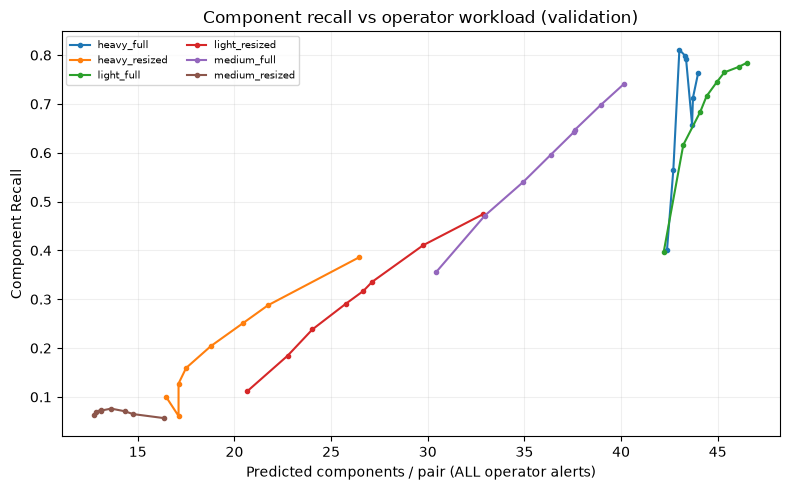

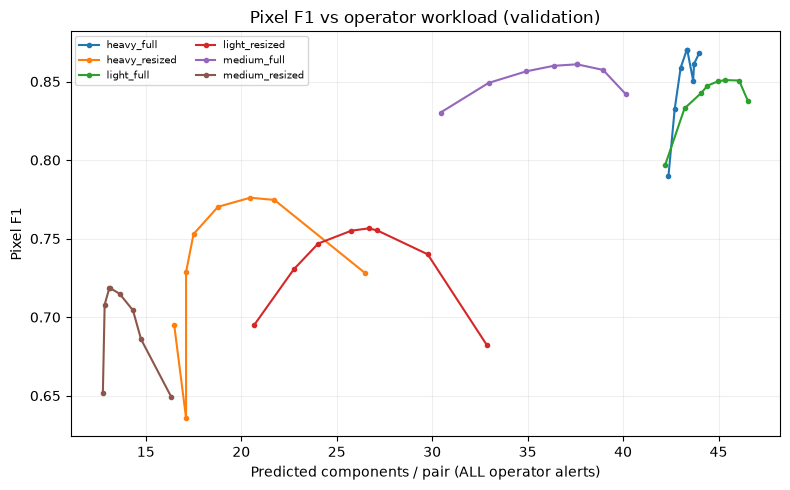

In [22]:
sweep = followup.sweep_validation()
display(sweep[['variant','threshold','pixel_f1','pixel_recall','pixel_precision','component_recall','alerts_per_pair','false_alerts_per_pair']])
followup.plot_validation_tradeoffs(sweep)


## 8. H5: Freeze a deployment-like operating point **on validation**

Within the scanned threshold grid, choose maximum **Component Recall** while meeting `max_alerts_per_pair`, `min_pixel_precision` and `max_forward_ms` (when supplied). If no candidate satisfies the constraints, report infeasibility rather than selecting a violating model. Ties are resolved by lower false-alert count, higher pixel precision and higher threshold.

The forward-only latency values are inherited from notebook 06 and exclude image read/resize, thresholding, component detection, alerts infrastructure and human review. The workload budget is **per image pair**. An unbounded/default sweep can favor excessive alerts; choose requirements before running test.


In [23]:
frozen = followup.freeze_choices(sweep)
validation_choices = pd.DataFrame(frozen['choices'])
display(validation_choices)
print('Frozen policy:', followup.out / 'choices_frozen.json')
display(followup.h5_validation_budget_sensitivity(sweep))


,feasible,reason,variant,latency_ms_forward_only,threshold,validation_alerts_per_pair,validation_component_recall,validation_false_alerts_per_pair
0,False,No scanned validation threshold meets constraints,light_full,NaN,NaN,NaN,NaN,NaN
1,False,No scanned validation threshold meets constraints,light_resized,NaN,NaN,NaN,NaN,NaN
2,False,No scanned validation threshold meets constraints,medium_full,NaN,NaN,NaN,NaN,NaN
3,True,NaN,medium_resized,17.971904,0.55,13.625,0.076040,10.3125
4,False,No scanned validation threshold meets constraints,heavy_full,NaN,NaN,NaN,NaN,NaN
5,True,NaN,heavy_resized,45.029104,0.55,17.500,0.159254,10.5625


Frozen policy: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H1_H5_followup_v2/choices_frozen.json


,variant,validation_alert_budget,feasible,best_component_recall,threshold,actual_alerts_per_pair
0,light_full,12,False,NaN,NaN,NaN
1,light_resized,12,False,NaN,NaN,NaN
2,medium_full,12,False,NaN,NaN,NaN
3,medium_resized,12,False,NaN,NaN,NaN
4,heavy_full,12,False,NaN,NaN,NaN
5,heavy_resized,12,False,NaN,NaN,NaN
6,light_full,16,False,NaN,NaN,NaN
7,light_resized,16,False,NaN,NaN,NaN
8,medium_full,16,False,NaN,NaN,NaN
9,medium_resized,16,True,0.076040,0.55,13.625000


## 9. Test gate — no test-side threshold selection

Set `RUN_TEST=True` in Section 0 **after** reviewing Section 8. The following measurements remain exploratory because the test set was already used in earlier research. No cell below reselects threshold from test scores.


In [24]:
if not RUN_TEST:
    print('Test remains disabled. Validate Section 8, then set RUN_TEST=True in Section 0.')
else:
    if frozen['signature'] != followup.signature:
        raise RuntimeError('Frozen choices invalid for current settings')
    print('Test enabled: evaluating only validation-frozen policies')


Test enabled: evaluating only validation-frozen policies


## 10. H1, H2, H4 on test — descriptive and uncertainty diagnostics

These compare saved per-image and per-component records, no inference is required. H1 here deliberately includes baseline and recall-matched operating points. CIs remain unadjusted for multiple comparisons and conditional on fixed checkpoint seeds.


In [25]:
if RUN_TEST:
    h1_test = followup.h1_matched_operating_points('test')
    display(h1_test[['family','policy','metric','estimate','ci_low','ci_high']])
    h2_test = followup.h2_error_attribution('test')
    display(h2_test[['heavy','baseline','error_category','estimate','ci_low','ci_high']])
    h4_test = followup.h4_component_failure_modes('test')
    display(h4_test[(h4_test['size_bin']=='small') & (h4_test['variant'].isin(['light_full','medium_full','medium_resized','heavy_full']))][['variant','failure_mode','gt_components','share_of_gt_components']])


,family,policy,metric,estimate,ci_low,ci_high
0,light,val_f1,component,0.131281,0.058418,0.196983
1,light,val_f1,pixel,-0.032620,-0.069488,0.008034
2,light,recall_080,component,0.151847,0.080200,0.225755
3,light,recall_080,pixel,-0.009807,-0.040315,0.025334
4,light,recall_090,component,0.061877,-0.040398,0.166233
5,light,recall_090,pixel,0.014584,-0.006921,0.038548
6,medium,val_f1,component,-0.039976,-0.143312,0.053297
7,medium,val_f1,pixel,-0.095716,-0.161392,-0.035964
8,medium,recall_080,component,-0.019678,-0.115851,0.074185
9,medium,recall_080,pixel,-0.079669,-0.146568,-0.021051


,heavy,baseline,error_category,estimate,ci_low,ci_high
0,heavy_full,light_full,near_GT_boundary_errors,37712.0,21358.225,54624.150
1,heavy_full,light_full,interior_false_negatives,30128.0,-18972.675,85141.400
2,heavy_full,light_full,far_background_false_positives,281244.0,187105.975,392554.275
3,heavy_full,light_full,all_fp,302287.0,193960.575,427514.350
4,heavy_full,light_full,all_fn,46797.0,-29661.250,120105.350
5,heavy_full,medium_full,near_GT_boundary_errors,144138.0,104201.950,186545.225
6,heavy_full,medium_full,interior_false_negatives,63264.0,7338.850,128164.500
7,heavy_full,medium_full,far_background_false_positives,-6389.0,-67520.250,57065.100
8,heavy_full,medium_full,all_fp,64374.0,-21587.325,156431.475
9,heavy_full,medium_full,all_fn,136639.0,33960.650,251854.575


,variant,failure_mode,gt_components,share_of_gt_components
8,heavy_full,covered_at_least_half_but_unmatched,503,0.167723
9,heavy_full,matched_iou_050,2061,0.687229
10,heavy_full,partially_covered_below_half,97,0.032344
11,heavy_full,zero_coverage,338,0.112704
32,light_full,covered_at_least_half_but_unmatched,494,0.164722
33,light_full,matched_iou_050,2058,0.686229
34,light_full,partially_covered_below_half,93,0.031010
35,light_full,zero_coverage,354,0.118039
56,medium_full,covered_at_least_half_but_unmatched,845,0.281761
57,medium_full,matched_iou_050,1566,0.522174


## 11. H3: OR Ensemble versus retuned individual models

Reuses the original **validation-frozen** H3 pairing for Light Full + Heavy Full at target validation Pixel Recall 0.90. Original notebook 06 selected retuned individual thresholds that aim to match the **OR's validation Pixel Recall**. Evaluate them on test. Actual achieved recall may differ; compare the confidence intervals and the remaining recall gap before claiming domination. Inference cost for the OR is only a sum of forward-only single-model measurements, **not** a measured full pipeline latency. Object matching is recomputed for the actual OR mask (unions can merge objects).


In [26]:
if RUN_TEST:
    h3_test, h3_ci_test = followup.h3_or_vs_retuned('test', 'light_full', 'heavy_full', 'recall_090')
    display(h3_test)
    display(h3_ci_test[['difference','base_variant','metric','estimate','ci_low','ci_high']])
    old_h3 = pd.read_csv(experiment.reports / 'H3_test_complementarity.csv')
    display(old_h3[(old_h3['policy']=='recall_090') & (
        (old_h3['a'].str.contains('light_full') & old_h3['b'].str.contains('heavy_full')) |
        (old_h3['a'].str.contains('heavy_full') & old_h3['b'].str.contains('light_full'))
    )][['a','b','jaccard_tp','complementarity_gain','recall_or','precision_or','actual_or_object_recall','sequential_forward_sum_ms_ESTIMATE']])


,split,method,model_or_ensemble,threshold,threshold_a,threshold_b,pixel_recall,pixel_precision,pixel_f1,component_recall,false_alerts_per_pair,alerts_per_pair
0,test,or,or,NaN,0.37,0.64,0.934179,0.746385,0.829790,0.606375,21.359375,54.648438
1,test,single_a,light_full,0.11,NaN,NaN,0.933731,0.685193,0.790384,0.398463,30.562500,52.437500
2,test,single_b,heavy_full,0.26,NaN,NaN,0.929190,0.757075,0.834349,0.510744,18.406250,46.445312


,difference,base_variant,metric,estimate,ci_low,ci_high
0,OR minus single_a,light_full,pixel_recall,0.000448,-0.004476,0.006249
1,OR minus single_a,light_full,pixel_precision,0.061192,0.054144,0.068264
2,OR minus single_a,light_full,pixel_f1,0.039405,0.034664,0.044477
3,OR minus single_a,light_full,component_recall,0.207912,0.183019,0.232087
4,OR minus single_b,heavy_full,pixel_recall,0.004989,0.000159,0.010773
5,OR minus single_b,heavy_full,pixel_precision,-0.010690,-0.023525,0.000665
6,OR minus single_b,heavy_full,pixel_f1,-0.004559,-0.011472,0.001650
7,OR minus single_b,heavy_full,component_recall,0.095631,0.060594,0.129563


,a,b,jaccard_tp,complementarity_gain,recall_or,precision_or,actual_or_object_recall,sequential_forward_sum_ms_ESTIMATE
3,light_full__s2024,heavy_full__s42,0.902519,0.39183,0.934179,0.746385,0.606375,446.205311


## 12. H5: Test performance of validation-selected thresholds and paired comparisons

The test outputs evaluate fixed choices from Section 8. Pairwise differences compare a constraint-selected point against the same model's baseline `val_f1` point. A positive change in Component Recall but a large change in alerts is an explicit deployment trade-off. The Pareto flags are **descriptive point-estimate summaries**, not significance tests, and test is not used to choose the deployed model.


In [27]:
if RUN_TEST:
    h5_test = followup.evaluate_test_choices(frozen)
    display(h5_test)
    h5_ci_test = followup.h5_compare_with_original(frozen)
    display(h5_ci_test[['variant','test_metric','estimate','ci_low','ci_high']])
    pareto_file = followup.reports / 'H5_test_pareto_selected_candidates.csv'
    if pareto_file.exists():
        display(pd.read_csv(pareto_file)[['variant','threshold','component_recall','alerts_per_pair','pixel_precision','latency_ms_forward_only','pareto_component_alerts_latency']])


TEST (frozen threshold): medium_resized 0.550000011920929
TEST (frozen threshold): heavy_resized 0.550000011920929


,variant,feasible_on_val,split,threshold,alerts_per_pair,false_alerts_per_pair,components_per_pair,pixel_f1,pixel_precision,pixel_recall,component_recall,component_precision,latency_ms_forward_only,validation_component_recall,validation_alerts_per_pair,validation_false_alerts_per_pair
0,light_full,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,light_resized,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,medium_full,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,medium_resized,True,test,0.55,14.93750,12.265625,54.898438,0.701984,0.631958,0.789462,0.048669,0.178870,17.971904,0.076040,13.625,10.3125
4,heavy_full,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,heavy_resized,True,test,0.55,19.90625,13.648438,54.898438,0.730371,0.641762,0.847369,0.113989,0.314364,45.029104,0.159254,17.500,10.5625


,variant,test_metric,estimate,ci_low,ci_high
0,medium_resized,component_recall,-0.000854,-0.003408,0.001753
1,medium_resized,alerts_per_pair,0.320312,0.054492,0.617383
2,medium_resized,false_alerts_per_pair,0.367188,0.093555,0.687695
3,medium_resized,pixel_f1,-0.004506,-0.007402,-0.001181
4,heavy_resized,component_recall,-0.073573,-0.094658,-0.054271
5,heavy_resized,alerts_per_pair,-3.039062,-4.492188,-1.827734
6,heavy_resized,false_alerts_per_pair,1.000000,0.367188,1.617383
7,heavy_resized,pixel_f1,-0.017323,-0.025407,-0.008421


,variant,threshold,component_recall,alerts_per_pair,pixel_precision,latency_ms_forward_only,pareto_component_alerts_latency
0,medium_resized,0.55,0.048669,14.93750,0.631958,17.971904,True
1,heavy_resized,0.55,0.113989,19.90625,0.641762,45.029104,True


## 13. Export only reports and graphs

The ZIP excludes native prediction score caches, GT images and model weights. The previous Research I directory is left intact. If `RUN_TEST=False`, the archive contains validation-only follow-up outputs.


In [28]:
archive_path = followup.export_zip()
print('Completed with test:', RUN_TEST)
display(FileLink(str(archive_path)))


Results archive (no images, model weights, or score arrays): /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H1_H5_followup_v2/H1_H5_followup_v2_results.zip
Completed with test: True


/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H1_H5_followup_v2/H1_H5_followup_v2_results.zip

## Interpretation checklist (do not auto-label hypotheses as proven)

**H1:** Does component advantage on small objects persist at matched-validation Pixel Recall policies? Are comparison models matched in training seeds and architectural parameters? (In some cases, no.) **H2:** Is any reduction in near-boundary error accompanied by increases in interior or far-background error? Does this explain error patterns without claiming causal F1 attribution? **H3:** At comparable achieved test Pixel Recall, does the OR beat the best validation-retuned single in Pixel Precision, Component Recall, false alerts, or cost? A high CG alone is insufficient. **H4:** What fraction of small GT regions have substantial pixel coverage but fail IoU≥0.5, particularly for Medium Resized? How do threshold changes affect component recall and alert counts? **H5:** Which validation-feasible choices remain feasible on test? Does any candidate dominate another across component recall, operator alerts and measured forward-only latency?

**Limitations:** post-hoc selection; image-pair bootstrap assumes these units are suitable independent sampling units (geographic clusters can violate this); no training-seed uncertainty unless separately evaluated; LEVIR-CD GT regions are not true building instances; OR false positives are not equivalent to object false alerts; no source-code rewrites; no money-valued cost model without measured rates; training cost excluded. Treat threshold sweeps and budget sensitivity as exploratory even when exported.
